In [1]:
import sys
import torch
import torchvision

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import os
print(os.listdir("/content/drive/MyDrive"))

['Screenshot_20260814_193940_Gmail.jpg', 'Screenshot_20260908_163248_Chrome.jpg', 'colab_checkpoints', 'Colab Notebooks', 'Fruit Dataset', 'Fruit_Classification_Project', 'CBAM_MTL_Checkpoints']


In [4]:
DATASET_PATH = "/content/drive/MyDrive/Fruit Dataset"
print("Dataset path:")
print(DATASET_PATH)
print("\nDataset exists:", os.path.exists(DATASET_PATH))

Dataset path:
/content/drive/MyDrive/Fruit Dataset

Dataset exists: True


In [5]:
print(os.listdir(DATASET_PATH))

['Bad Quality_Fruits', 'Good Quality_Fruits', 'Mixed Qualit_Fruits']


In [6]:
for quality_folder in os.listdir(DATASET_PATH):
        quality_path = os.path.join(
                     DATASET_PATH,
                     quality_folder
                     )
        print("\n" + quality_folder)
        for fruit_folder in os.listdir(quality_path):
          print("   ", fruit_folder)


Bad Quality_Fruits
    Pomegranate_Bad
    Lime_Bad
    Apple_Bad
    Orange_Bad
    Banana_Bad
    Guava_Bad

Good Quality_Fruits
    Apple_Good
    Banana_Good
    Guava_Good
    Lime_Good
    Pomegranate_Good
    Orange_Good

Mixed Qualit_Fruits
    Apple
    Lemon
    Guava
    Banana
    Orange
    Pomegranate


In [7]:
import pandas as pd

In [8]:
data =[]
for quality_folder in os.listdir(DATASET_PATH):
        quality_path = os.path.join(
                     DATASET_PATH,
                     quality_folder
                     )
        if quality_folder == "Good Quality_Fruits":
          quality = "Good"
        elif quality_folder == "Bad Quality_Fruits":
          quality = "Bad"
        elif quality_folder == "Mixed Qualit_Fruits":
          quality = "Mixed"
        else:
          continue
        for fruit_folder in os.listdir(quality_path):
          fruit_path = os.path.join(
                     quality_path,
                     fruit_folder
          )
          if not os.path.isdir(fruit_path):
            continue
          if "_"in fruit_folder:
            fruit = fruit_folder.split("_")[0]
          else:
            fruit = fruit_folder
          if fruit == "Lemon":
            fruit = "Lime"
          for image_name in os.listdir(fruit_path):
            if image_name.lower().endswith(
                ("jpg",".jpeg",".png",".bmp",".webp")
            ):
                image_path = os.path.join(
                    fruit_path,
                    image_name
                )
                data.append({
                    "image_path":image_path,
                    "fruit":fruit,
                    "quality":quality
                })
df = pd.DataFrame(data)
print("Dataset created successfully.")
print("Total images:", len(df))

Dataset created successfully.
Total images: 19546


In [9]:
df.head()

,image_path,fruit,quality
0,/content/drive/MyDrive/Fruit Dataset/Bad Quali...,Pomegranate,Bad
1,/content/drive/MyDrive/Fruit Dataset/Bad Quali...,Pomegranate,Bad
2,/content/drive/MyDrive/Fruit Dataset/Bad Quali...,Pomegranate,Bad
3,/content/drive/MyDrive/Fruit Dataset/Bad Quali...,Pomegranate,Bad
4,/content/drive/MyDrive/Fruit Dataset/Bad Quali...,Pomegranate,Bad


In [10]:
print("Number of images:", len(df))
print("Number of columns:", len(df.columns))
print("\nColumns:")
print(df.columns.tolist())

Number of images: 19546
Number of columns: 3

Columns:
['image_path', 'fruit', 'quality']


In [11]:
fruit_distribution = df["fruit"].value_counts()
print(fruit_distribution)

fruit
Pomegranate    7252
Orange         2516
Banana         2488
Lime           2458
Guava          2429
Apple          2403
Name: count, dtype: int64


In [12]:
quality_distribution = df["quality"].value_counts()
print(quality_distribution)

quality
Good     11664
Bad       6808
Mixed     1074
Name: count, dtype: int64


In [13]:
distribution = pd.crosstab(
    df["fruit"],
    df["quality"]
    )
print(distribution)

quality       Bad  Good  Mixed
fruit                         
Apple        1141  1149    113
Banana       1090  1113    285
Guava        1129  1152    148
Lime         1086  1094    278
Orange       1175  1216    125
Pomegranate  1187  5940    125


In [14]:
df["combined_label"] = (
    df["fruit"] + "_" + df["quality"]
    )
print(df.head())

                                          image_path        fruit quality  \
0  /content/drive/MyDrive/Fruit Dataset/Bad Quali...  Pomegranate     Bad   
1  /content/drive/MyDrive/Fruit Dataset/Bad Quali...  Pomegranate     Bad   
2  /content/drive/MyDrive/Fruit Dataset/Bad Quali...  Pomegranate     Bad   
3  /content/drive/MyDrive/Fruit Dataset/Bad Quali...  Pomegranate     Bad   
4  /content/drive/MyDrive/Fruit Dataset/Bad Quali...  Pomegranate     Bad   

    combined_label  
0  Pomegranate_Bad  
1  Pomegranate_Bad  
2  Pomegranate_Bad  
3  Pomegranate_Bad  
4  Pomegranate_Bad  


In [15]:
print(
    df["combined_label"].value_counts()
    )

combined_label
Pomegranate_Good     5940
Orange_Good          1216
Pomegranate_Bad      1187
Orange_Bad           1175
Guava_Good           1152
Apple_Good           1149
Apple_Bad            1141
Guava_Bad            1129
Banana_Good          1113
Lime_Good            1094
Banana_Bad           1090
Lime_Bad             1086
Banana_Mixed          285
Lime_Mixed            278
Guava_Mixed           148
Orange_Mixed          125
Pomegranate_Mixed     125
Apple_Mixed           113
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["combined_label"]
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=1/3,
    random_state=42,
    stratify=temp_df["combined_label"]
)
print("Total:", len(df))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Total: 19546
Training: 13682
Validation: 3909
Testing: 1955


In [17]:
train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])
print(
"Train ∩ Validation:",
len(train_paths & val_paths)
)
print(
"Train ∩ Test:",
len(train_paths & test_paths)
)
print(
    "Validation ∩ Test:",
    len(val_paths & test_paths)
)

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [18]:
print("TRAIN")
print(
    pd.crosstab(
        train_df["fruit"],
        train_df["quality"]
    )
)
print("\nVALIDATION")
print(
    pd.crosstab(
        val_df["fruit"],
        val_df["quality"]
    )
)
print("\nTEST")
print(
    pd.crosstab(
        test_df["fruit"],
        test_df["quality"]
    )
)

TRAIN
quality      Bad  Good  Mixed
fruit                        
Apple        799   804     79
Banana       763   779    199
Guava        790   806    104
Lime         760   766    195
Orange       822   851     88
Pomegranate  831  4158     88

VALIDATION
quality      Bad  Good  Mixed
fruit                        
Apple        228   230     23
Banana       218   223     57
Guava        226   231     29
Lime         217   219     55
Orange       235   243     25
Pomegranate  237  1188     25

TEST
quality      Bad  Good  Mixed
fruit                        
Apple        114   115     11
Banana       109   111     29
Guava        113   115     15
Lime         109   109     28
Orange       118   122     12
Pomegranate  119   594     12


In [19]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

In [20]:
fruit_classes = [
    "Apple",
    "Banana",
    "Guava",
    "Lime",
    "Orange",
    "Pomegranate"
]

print("Fruit classes:")
for i, fruit in enumerate(fruit_classes):
    print(i, "->", fruit)

Fruit classes:
0 -> Apple
1 -> Banana
2 -> Guava
3 -> Lime
4 -> Orange
5 -> Pomegranate


In [21]:
fruit_to_idx = {
    fruit: index
    for index, fruit in enumerate(fruit_classes)
}

print(fruit_to_idx)

{'Apple': 0, 'Banana': 1, 'Guava': 2, 'Lime': 3, 'Orange': 4, 'Pomegranate': 5}


In [22]:
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

In [23]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(45),
    transforms.GaussianBlur(
        kernel_size=3
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

In [24]:
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

In [25]:
class FruitDataset(Dataset):
    def __init__(
        self,
        dataframe,
        transform=None
    ):
        self.dataframe = dataframe.reset_index(
            drop=True
        )
        self.transform = transform
    def __len__(self):
        return len(self.dataframe)
    def __getitem__(self, index):
       row = self.dataframe.iloc[index]
       image_path = row["image_path"]
       image = Image.open(
            image_path
        ).convert("RGB")
       if self.transform is not None:
            image = self.transform(image)
       fruit_label = fruit_to_idx[
            row["fruit"]
        ]
       return image, fruit_label

In [26]:
train_dataset = FruitDataset(
    train_df,
    transform=train_transform
)
print(
    "Training images:",
    len(train_dataset)
)

Training images: 13682


In [27]:
val_dataset = FruitDataset(
    val_df,
    transform=val_test_transform
)
print(
    "Validation images:",
    len(val_dataset)
)

Validation images: 3909


In [28]:
test_dataset = FruitDataset(
    test_df,
    transform=val_test_transform
)
print(
    "Testing images:",
    len(test_dataset)
)

Testing images: 1955


In [29]:
image, label = train_dataset[0]
print("Image shape:", image.shape)
print("Label:", label)
print("Fruit:", fruit_classes[label])

Image shape: torch.Size([3, 224, 224])
Label: 2
Fruit: Guava


In [30]:
BATCH_SIZE = 8
train_loader = DataLoader(
train_dataset,
batch_size=BATCH_SIZE,
shuffle=True,
    num_workers=2,

    pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

In [31]:
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
pin_memory=torch.cuda.is_available()
)

In [32]:
print(
"Training batches:",
len(train_loader)
)
print(
"Validation batches:",
len(val_loader)
)
print(
"Testing batches:",
len(test_loader)
)

Training batches: 1711
Validation batches: 489
Testing batches: 245


In [33]:
images, labels = next(
iter(train_loader)
)
print("Images shape:")
print(images.shape)
print("\nLabels shape:")
print(labels.shape)
print("\nLabels:")
print(labels)

Images shape:
torch.Size([8, 3, 224, 224])

Labels shape:
torch.Size([8])

Labels:
tensor([1, 1, 5, 0, 4, 3, 5, 4])


In [34]:
print("Numerical labels:")
print(labels.tolist())
print("\nFruit names:")
for label in labels[:10]:
    print(
        fruit_classes[label.item()]
    )

Numerical labels:
[1, 1, 5, 0, 4, 3, 5, 4]

Fruit names:
Banana
Banana
Pomegranate
Apple
Orange
Lime
Pomegranate
Orange


In [35]:
import matplotlib.pyplot as plt
import numpy as np
def denormalize(image):
    mean = torch.tensor(
        IMAGENET_MEAN
    ).view(3, 1, 1)
    std = torch.tensor(
        IMAGENET_STD
    ).view(3, 1, 1)
    image = image * std + mean
    return torch.clamp(
        image,
        0,
        1
    )

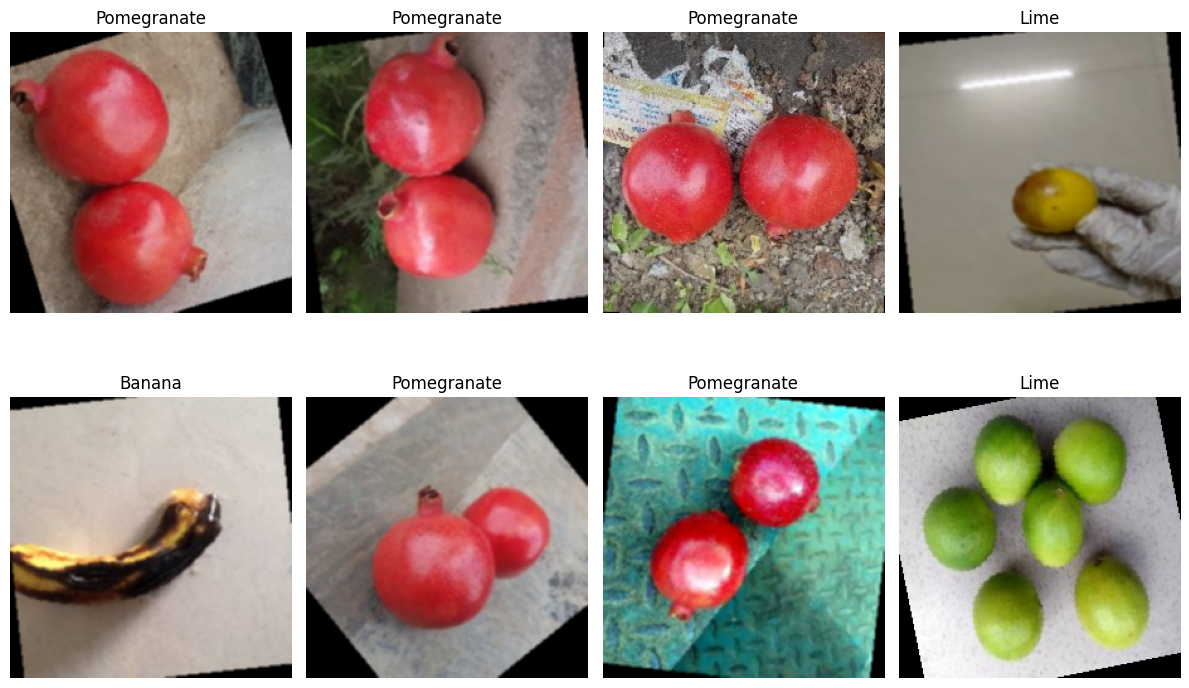

In [36]:
images, labels = next(
    iter(train_loader)
)
plt.figure(figsize=(12, 8))
for i in range(8):
    image = denormalize(
        images[i]
    )
    image = image.permute(
        1, 2, 0
    )
    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    fruit_name = fruit_classes[
    labels[i].item()
    ]
    plt.title(fruit_name)
    plt.axis("off") # Corrected from "oA" to "off"
plt.tight_layout()
plt.show()

In [37]:
print(
    hasattr(
        transforms,
        "AugMix"
    )
)

True


In [38]:
augmix_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.AugMix(),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

In [39]:
sample_path = train_df.iloc[0]["image_path"]
sample_image = Image.open(
    sample_path
).convert("RGB")
augmented_image = augmix_transform(
    sample_image
)
print(
    "AugMix image shape:",
    augmented_image.shape
)

AugMix image shape: torch.Size([3, 224, 224])


In [40]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )
else:
    print("WARNING: GPU is not available.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [41]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Using device:", device)

Using device: cuda


In [42]:
import os
BASE_OUTPUT_DIR = (
    "/content/drive/MyDrive/"
    "Fruit_Classification_Project/"
    "ResNet50"
)
CHECKPOINT_DIR = os.path.join(
    BASE_OUTPUT_DIR,
    "checkpoints"
)
METRICS_DIR = os.path.join(
    BASE_OUTPUT_DIR,
    "metrics"
)
CM_DIR = os.path.join(
    BASE_OUTPUT_DIR,
    "confusion_matrix"
)
GRADCAM_DIR = os.path.join(
    BASE_OUTPUT_DIR,
    "gradcam"
)
PREDICTIONS_DIR = os.path.join(
    BASE_OUTPUT_DIR,
    "predictions"
)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)
os.makedirs(CM_DIR, exist_ok=True)
os.makedirs(GRADCAM_DIR, exist_ok=True)
os.makedirs(PREDICTIONS_DIR, exist_ok=True)
print("Output directories created.")

Output directories created.


In [43]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=False
)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Batch size: 8
Training batches: 1711
Validation batches: 489
Test batches: 245


In [44]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)

Images: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8])


In [45]:
import torch.nn as nn
from torchvision import models
print("Loading pretrained ResNet50...")
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(
    weights=weights
)
print("ResNet50 loaded.")

Loading pretrained ResNet50...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 220MB/s]


ResNet50 loaded.


In [46]:
num_classes = len(fruit_classes)
model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)
model = model.to(device)
print("Number of classes:", num_classes)
print("Final layer:", model.fc)

Number of classes: 6
Final layer: Linear(in_features=2048, out_features=6, bias=True)


In [47]:
test_input = torch.randn(
    2,
    3,
    224,
    224
).to(device)
with torch.no_grad():
    test_output = model(test_input)
print("Input shape :", test_input.shape)
print("Output shape:", test_output.shape)

Input shape : torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 6])


In [48]:
criterion = nn.CrossEntropyLoss()
print("Loss:", criterion)

Loss: CrossEntropyLoss()


In [49]:
import torch.optim as optim
LEARNING_RATE = 0.01
WEIGHT_DECAY = 1e-2
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
print("Optimizer:", optimizer)

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0.01
)


In [50]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.1,
    patience=3
)
print("ReduceLROnPlateau scheduler created.")

ReduceLROnPlateau scheduler created.


In [51]:
import numpy as np

def mixup_data(
    images,
    labels,
    alpha=1.0
):

    lam = np.random.beta(
        alpha,
        alpha
    )

    batch_size = images.size(0)

    index = torch.randperm(
        batch_size,
        device=images.device
    )

    mixed_images = (
        lam * images
        +
        (1 - lam) * images[index]
    )

    labels_a = labels
    labels_b = labels[index]

    return (
        mixed_images,
        labels_a,
        labels_b,
        lam
    )

In [52]:
def rand_bbox(
    size,
    lam
):

    W = size[3]
    H = size[2]

    cut_ratio = np.sqrt(
        1.0 - lam
    )

    cut_w = int(
        W * cut_ratio
    )

    cut_h = int(
        H * cut_ratio
    )

    cx = np.random.randint(W)
    cy = np.random.randint(H)

    bbx1 = np.clip(
        cx - cut_w // 2,
        0,
        W
    )

    bby1 = np.clip(
        cy - cut_h // 2,
        0,
        H
    )

    bbx2 = np.clip(
        cx + cut_w // 2,
        0,
        W
    )

    bby2 = np.clip(
        cy + cut_h // 2,
        0,
        H
    )

    return (
        bbx1,
        bby1,
        bbx2,
        bby2
    )

In [53]:
def cutmix_data(
    images,
    labels,
    alpha=1.0
):

    lam = np.random.beta(
        alpha,
        alpha
    )

    batch_size = images.size(0)

    index = torch.randperm(
        batch_size,
        device=images.device
    )

    bbx1, bby1, bbx2, bby2 = rand_bbox(
        images.size(),
        lam
    )

    images[
        :,
        :,
        bby1:bby2,
        bbx1:bbx2
    ] = images[
        index,
        :,
        bby1:bby2,
        bbx1:bbx2
    ]

    area = (
        (bbx2 - bbx1)
        *
        (bby2 - bby1)
    )

    lam = 1 - (
        area /
        (
            images.size(-1)
            *
            images.size(-2)
        )
    )

    labels_a = labels
    labels_b = labels[index]

    return (
        images,
        labels_a,
        labels_b,
        lam
    )

In [54]:
def validate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += (
                loss.item()
                *
                images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    average_loss = total_loss / total

    accuracy = (
        100.0 * correct / total
    )

    return (
        average_loss,
        accuracy
    )

In [55]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
    scaler
):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        random_value = np.random.rand()

        # =================================
        # MIXUP
        # =================================

        if random_value < 0.25:

            images, labels_a, labels_b, lam = \
                mixup_data(
                    images,
                    labels
                )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = (
                    lam * criterion(
                        outputs,
                        labels_a
                    )
                    +
                    (1 - lam) * criterion(
                        outputs,
                        labels_b
                    )
                )

        # =================================
        # CUTMIX
        # =================================

        elif random_value < 0.50:

            images, labels_a, labels_b, lam = \
                cutmix_data(
                    images,
                    labels
                )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = (
                    lam * criterion(
                        outputs,
                        labels_a
                    )
                    +
                    (1 - lam) * criterion(
                        outputs,
                        labels_b
                    )
                )

        # =================================
        # NORMAL
        # =================================

        else:

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

        # =================================
        # BACKPROPAGATION
        # =================================

        if scaler is not None:

            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

        else:

            loss.backward()

            optimizer.step()

        # =================================
        # METRICS
        # =================================

        total_loss += (
            loss.item()
            *
            images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    average_loss = (
        total_loss / total
    )

    accuracy = (
        100.0 * correct / total
    )

    return (
        average_loss,
        accuracy
    )

In [56]:
if torch.cuda.is_available():
    scaler = torch.amp.GradScaler(
        "cuda"
    )
    print("Mixed precision: ENABLED")
else:
    scaler = None
    print("Mixed precision: DISABLED")

Mixed precision: ENABLED


In [57]:
# ============================================================
# RESNET50 TRAINING
# CHECKPOINT + RESUME + LIVE PROGRESS
# BASED ON YOUR EXISTING CODE
# ============================================================

import os
import time
import torch
import pandas as pd
from tqdm.auto import tqdm


# ============================================================
# 1. TRAINING SETTINGS
# ============================================================

NUM_EPOCHS = 30

# ------------------------------------------------------------
# True  = resume from checkpoint if available
# False = start training from epoch 1
# ------------------------------------------------------------

RESUME_TRAINING = True


# ============================================================
# 2. CHECKPOINT FILES
# ============================================================

LAST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "last_checkpoint.pth"
)

BEST_MODEL = os.path.join(
    CHECKPOINT_DIR,
    "best_model.pth"
)

HISTORY_FILE = os.path.join(
    METRICS_DIR,
    "training_history.csv"
)


# ============================================================
# 3. DISPLAY TRAINING INFORMATION
# ============================================================

print("=" * 70)
print("                    RESNET50 TRAINING")
print("=" * 70)

print("Device           :", device)
print("GPU              :",
      torch.cuda.get_device_name(0)
      if torch.cuda.is_available()
      else "CPU")

print("Batch size       :", BATCH_SIZE)
print("Training images  :", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches :", len(train_loader))
print("Validation batches:", len(val_loader))
print("Total epochs     :", NUM_EPOCHS)

print("=" * 70)


# ============================================================
# 4. INITIAL VALUES
# ============================================================

start_epoch = 0
best_val_accuracy = 0.0

history = {
    "epoch": [],
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": [],
    "epoch_time": []
}


# ============================================================
# 5. RESUME CHECKPOINT
# ============================================================

if RESUME_TRAINING and os.path.exists(LAST_CHECKPOINT):

    print("\n" + "=" * 70)
    print("CHECKPOINT FOUND")
    print("=" * 70)

    checkpoint = torch.load(
        LAST_CHECKPOINT,
        map_location=device
    )

    # --------------------------------------------------------
    # Restore model
    # --------------------------------------------------------

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    # --------------------------------------------------------
    # Restore optimizer
    # --------------------------------------------------------

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    # --------------------------------------------------------
    # Restore scheduler
    # --------------------------------------------------------

    if "scheduler_state_dict" in checkpoint:

        scheduler.load_state_dict(
            checkpoint["scheduler_state_dict"]
        )

    # --------------------------------------------------------
    # Restore AMP scaler
    # --------------------------------------------------------

    if (
        scaler is not None
        and checkpoint.get("scaler_state_dict") is not None
    ):

        scaler.load_state_dict(
            checkpoint["scaler_state_dict"]
        )

    # --------------------------------------------------------
    # Restore epoch
    # --------------------------------------------------------

    start_epoch = checkpoint["epoch"]

    # --------------------------------------------------------
    # Restore best accuracy
    # --------------------------------------------------------

    best_val_accuracy = checkpoint.get(
        "best_val_accuracy",
        0.0
    )

    # --------------------------------------------------------
    # Restore history
    # --------------------------------------------------------

    if "history" in checkpoint:

        history = checkpoint["history"]

    print(
        "Last completed epoch:",
        start_epoch
    )

    print(
        "Next epoch:",
        start_epoch + 1
    )

    print(
        f"Best validation accuracy: "
        f"{best_val_accuracy:.2f}%"
    )

    print("=" * 70)

else:

    print("\nNo checkpoint found.")

    if RESUME_TRAINING:

        print(
            "Starting training from epoch 1."
        )

    else:

        print(
            "Fresh training selected."
        )

    start_epoch = 0


# ============================================================
# 6. TRAINING FUNCTION
# ============================================================
# This is your existing train_one_epoch() logic.
# Only tqdm progress has been added.
# MixUp and CutMix are unchanged.
# ============================================================

def train_one_epoch_progress(
    model,
    loader,
    criterion,
    optimizer,
    device,
    scaler
):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        loader,
        total=len(loader),
        desc="Training",
        unit="batch"
    )

    for images, labels in progress_bar:

        # ====================================================
        # MOVE TO DEVICE
        # ====================================================

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        random_value = np.random.rand()


        # ====================================================
        # MIXUP
        # ====================================================

        if random_value < 0.25:

            images, labels_a, labels_b, lam = \
                mixup_data(
                    images,
                    labels
                )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = (
                    lam * criterion(
                        outputs,
                        labels_a
                    )
                    +
                    (1 - lam) * criterion(
                        outputs,
                        labels_b
                    )
                )


        # ====================================================
        # CUTMIX
        # ====================================================

        elif random_value < 0.50:

            images, labels_a, labels_b, lam = \
                cutmix_data(
                    images,
                    labels
                )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = (
                    lam * criterion(
                        outputs,
                        labels_a
                    )
                    +
                    (1 - lam) * criterion(
                        outputs,
                        labels_b
                    )
                )


        # ====================================================
        # NORMAL TRAINING
        # ====================================================

        else:

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )


        # ====================================================
        # BACKPROPAGATION
        # ====================================================

        if scaler is not None:

            scaler.scale(
                loss
            ).backward()

            scaler.step(
                optimizer
            )

            scaler.update()

        else:

            loss.backward()

            optimizer.step()


        # ====================================================
        # METRICS
        # ====================================================

        total_loss += (
            loss.item()
            *
            images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)


        # ====================================================
        # CURRENT PROGRESS
        # ====================================================

        current_loss = (
            total_loss / total
        )

        current_accuracy = (
            100.0
            *
            correct
            /
            total
        )

        batch_percentage = (
            (progress_bar.n + 1)
            /
            len(loader)
            *
            100
        )

        progress_bar.set_postfix(
            progress=f"{batch_percentage:.1f}%",
            loss=f"{current_loss:.4f}",
            acc=f"{current_accuracy:.2f}%"
        )


    # ========================================================
    # FINAL TRAINING METRICS
    # ========================================================

    average_loss = (
        total_loss / total
    )

    accuracy = (
        100.0
        *
        correct
        /
        total
    )

    return (
        average_loss,
        accuracy
    )


# ============================================================
# 7. VALIDATION FUNCTION
# ============================================================
# Same logic as your existing validate().
# Only progress display is added.
# ============================================================

def validate_progress(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        loader,
        total=len(loader),
        desc="Validation",
        unit="batch"
    )

    with torch.no_grad():

        for images, labels in progress_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += (
                loss.item()
                *
                images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)


            # ------------------------------------------------
            # CURRENT VALIDATION METRICS
            # ------------------------------------------------

            current_loss = (
                total_loss / total
            )

            current_accuracy = (
                100.0
                *
                correct
                /
                total
            )

            batch_percentage = (
                (progress_bar.n + 1)
                /
                len(loader)
                *
                100
            )

            progress_bar.set_postfix(
                progress=f"{batch_percentage:.1f}%",
                loss=f"{current_loss:.4f}",
                acc=f"{current_accuracy:.2f}%"
            )


    average_loss = (
        total_loss / total
    )

    accuracy = (
        100.0
        *
        correct
        /
        total
    )

    return (
        average_loss,
        accuracy
    )


# ============================================================
# 8. TRAINING LOOP
# ============================================================

if start_epoch >= NUM_EPOCHS:

    print("\nTraining is already completed.")

else:

    for epoch in range(
        start_epoch,
        NUM_EPOCHS
    ):

        epoch_start_time = time.time()

        print("\n")
        print("=" * 70)

        print(
            f"EPOCH {epoch + 1}/{NUM_EPOCHS}"
        )

        print(
            f"Overall Progress: "
            f"{(epoch + 1) / NUM_EPOCHS * 100:.2f}%"
        )

        print("=" * 70)


        # ====================================================
        # TRAIN
        # ====================================================

        train_loss, train_accuracy = \
            train_one_epoch_progress(
                model,
                train_loader,
                criterion,
                optimizer,
                device,
                scaler
            )


        # ====================================================
        # VALIDATION
        # ====================================================

        val_loss, val_accuracy = \
            validate_progress(
                model,
                val_loader,
                criterion,
                device
            )


        # ====================================================
        # SCHEDULER
        # ====================================================

        scheduler.step(
            val_loss
        )

        current_lr = (
            optimizer.param_groups[0]["lr"]
        )


        # ====================================================
        # TIME
        # ====================================================

        epoch_time = (
            time.time()
            -
            epoch_start_time
        )

        epoch_minutes = (
            epoch_time / 60
        )


        # ====================================================
        # HISTORY
        # ====================================================

        history["epoch"].append(
            epoch + 1
        )

        history["train_loss"].append(
            train_loss
        )

        history["train_accuracy"].append(
            train_accuracy
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_accuracy"].append(
            val_accuracy
        )

        history["learning_rate"].append(
            current_lr
        )

        history["epoch_time"].append(
            epoch_time
        )


        # ====================================================
        # PRINT RESULTS
        # ====================================================

        print("\n" + "-" * 70)

        print(
            f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}]"
        )

        print(
            f"Train Loss      : "
            f"{train_loss:.4f}"
        )

        print(
            f"Train Accuracy  : "
            f"{train_accuracy:.2f}%"
        )

        print(
            f"Validation Loss : "
            f"{val_loss:.4f}"
        )

        print(
            f"Validation Acc  : "
            f"{val_accuracy:.2f}%"
        )

        print(
            f"Learning Rate   : "
            f"{current_lr:.8f}"
        )

        print(
            f"Epoch Time      : "
            f"{epoch_minutes:.2f} minutes"
        )

        print(
            f"Overall Progress: "
            f"{(epoch + 1) / NUM_EPOCHS * 100:.2f}%"
        )

        print("-" * 70)


        # ====================================================
        # SAVE BEST MODEL
        # ====================================================

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = (
                val_accuracy
            )

            torch.save(
                {
                    "epoch":
                        epoch + 1,

                    "model_state_dict":
                        model.state_dict(),

                    "optimizer_state_dict":
                        optimizer.state_dict(),

                    "scheduler_state_dict":
                        scheduler.state_dict(),

                    "scaler_state_dict":
                        (
                            scaler.state_dict()
                            if scaler is not None
                            else None
                        ),

                    "val_accuracy":
                        val_accuracy,

                    "val_loss":
                        val_loss,

                    "best_val_accuracy":
                        best_val_accuracy,

                    "classes":
                        fruit_classes
                },
                BEST_MODEL
            )

            print(
                "✓ Best model saved."
            )

            print(
                f"  Best Validation Accuracy: "
                f"{best_val_accuracy:.2f}%"
            )


        # ====================================================
        # SAVE LAST CHECKPOINT
        # ====================================================

        checkpoint = {

            "epoch":
                epoch + 1,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "scaler_state_dict":
                (
                    scaler.state_dict()
                    if scaler is not None
                    else None
                ),

            "val_accuracy":
                val_accuracy,

            "val_loss":
                val_loss,

            "best_val_accuracy":
                best_val_accuracy,

            "classes":
                fruit_classes,

            "history":
                history
        }


        torch.save(
            checkpoint,
            LAST_CHECKPOINT
        )

        print(
            "✓ Checkpoint saved."
        )


        # ====================================================
        # SAVE CSV
        # ====================================================

        history_df = pd.DataFrame(
            history
        )

        history_df.to_csv(
            HISTORY_FILE,
            index=False
        )

        print(
            "✓ Training history saved."
        )


# ============================================================
# 9. FINAL STATUS
# ============================================================

print("\n")
print("=" * 70)
print("                    TRAINING STATUS")
print("=" * 70)

if len(history["epoch"]) > 0:

    completed_epochs = (
        history["epoch"][-1]
    )

    print(
        f"Completed Epochs : "
        f"{completed_epochs}/{NUM_EPOCHS}"
    )

    print(
        f"Overall Progress : "
        f"{completed_epochs / NUM_EPOCHS * 100:.2f}%"
    )

print(
    f"Best Validation Accuracy : "
    f"{best_val_accuracy:.2f}%"
)

print(
    f"\nBest Model:"
)

print(
    BEST_MODEL
)

print(
    f"\nLast Checkpoint:"
)

print(
    LAST_CHECKPOINT
)

print(
    f"\nTraining History:"
)

print(
    HISTORY_FILE
)

print("=" * 70)

                    RESNET50 TRAINING
Device           : cuda
GPU              : Tesla T4
Batch size       : 8
Training images  : 13682
Validation images: 3909
Training batches : 1711
Validation batches: 489
Total epochs     : 30

CHECKPOINT FOUND
Last completed epoch: 30
Next epoch: 31
Best validation accuracy: 98.00%

Training is already completed.


                    TRAINING STATUS
Completed Epochs : 30/30
Overall Progress : 100.00%
Best Validation Accuracy : 98.00%

Best Model:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/checkpoints/best_model.pth

Last Checkpoint:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/checkpoints/last_checkpoint.pth

Training History:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/metrics/training_history.csv


In [58]:
history_df = pd.DataFrame(history)
history_path = os.path.join(
    METRICS_DIR,
    "training_history.csv"
)
history_df.to_csv(
    history_path,
    index=False
)
print(
    "Training history saved:"
)
print(history_path)

Training history saved:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/metrics/training_history.csv


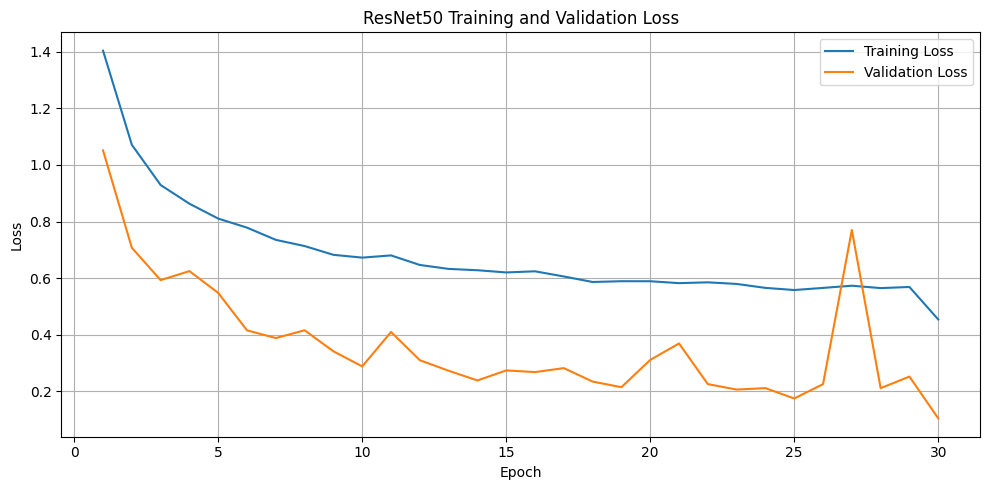

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet50 Training and Validation Loss"
)
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        METRICS_DIR,
        "loss_curve.png"
    ),
    dpi=300
)
plt.show()

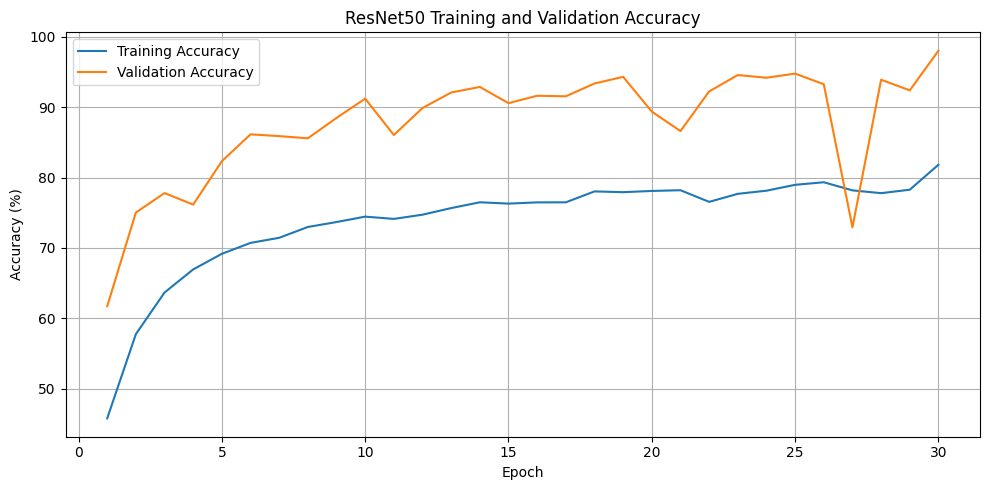

In [60]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "ResNet50 Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        METRICS_DIR,
        "accuracy_curve.png"
    ),
    dpi=300
)
plt.show()

In [61]:
# ============================================================
# CELL R21 — LOAD BEST RESNET50 MODEL
# ============================================================

import os
import torch

print("=" * 70)
print("LOADING BEST RESNET50 MODEL")
print("=" * 70)

# Best model path from your existing training code
BEST_MODEL = os.path.join(
    CHECKPOINT_DIR,
    "best_model.pth"
)

print("Best model path:")
print(BEST_MODEL)

# ------------------------------------------------------------
# Check whether best model exists
# ------------------------------------------------------------

if not os.path.exists(BEST_MODEL):

    raise FileNotFoundError(
        f"Best model not found:\n{BEST_MODEL}"
    )

# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------

best_checkpoint = torch.load(
    BEST_MODEL,
    map_location=device
)

# ------------------------------------------------------------
# Load model weights
# ------------------------------------------------------------

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

# ------------------------------------------------------------
# Evaluation mode
# ------------------------------------------------------------

model = model.to(device)
model.eval()
print("\n✓ Best ResNet50 model loaded successfully")
if "val_accuracy" in best_checkpoint:
    print(
        f"Best Validation Accuracy: "
        f"{best_checkpoint['val_accuracy']:.2f}%"
    )
if "epoch" in best_checkpoint:

    print(
        f"Best Model Epoch: "
        f"{best_checkpoint['epoch']}"
    )
print("=" * 70)

LOADING BEST RESNET50 MODEL
Best model path:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/checkpoints/best_model.pth

✓ Best ResNet50 model loaded successfully
Best Validation Accuracy: 98.00%
Best Model Epoch: 30


In [62]:
# ============================================================
# CELL R22 — GENERATE TEST SET PREDICTIONS
# ============================================================

import torch
from tqdm.auto import tqdm

print("=" * 70)
print("GENERATING TEST SET PREDICTIONS")
print("=" * 70)

model.eval()

all_true_labels = []
all_pred_labels = []

# ------------------------------------------------------------
# Disable gradient calculation
# ------------------------------------------------------------

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Testing",
        unit="batch"
    ):

        # Move data to GPU / CPU
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Predicted class
        predictions = torch.argmax(
            outputs,
            dim=1
        )

        # Store labels
        all_true_labels.extend(
            labels.cpu().numpy()
        )

        all_pred_labels.extend(
            predictions.cpu().numpy()
        )

print("\n✓ Test predictions generated")

print(
    f"Total test samples: "
    f"{len(all_true_labels)}"
)

print("=" * 70)

GENERATING TEST SET PREDICTIONS


Testing:   0%|          | 0/245 [00:00<?, ?batch/s]


✓ Test predictions generated
Total test samples: 1955


In [63]:
# ============================================================
# CELL R23 — TEST ACCURACY
# ============================================================

import numpy as np

all_true_labels = np.array(
    all_true_labels
)

all_pred_labels = np.array(
    all_pred_labels
)

test_accuracy = (
    np.mean(
        all_true_labels == all_pred_labels
    ) * 100
)
print("=" * 70)
print("TEST SET PERFORMANCE")
print("=" * 70)
print(
    f"Test Accuracy : {test_accuracy:.2f}%"
)
print(
    f"Correct       : "
    f"{np.sum(all_true_labels == all_pred_labels)}"
)
print(
    f"Incorrect     : "
    f"{np.sum(all_true_labels != all_pred_labels)}"
)
print(
    f"Total         : "
    f"{len(all_true_labels)}"
)
print("=" * 70)

TEST SET PERFORMANCE
Test Accuracy : 97.34%
Correct       : 1903
Incorrect     : 52
Total         : 1955


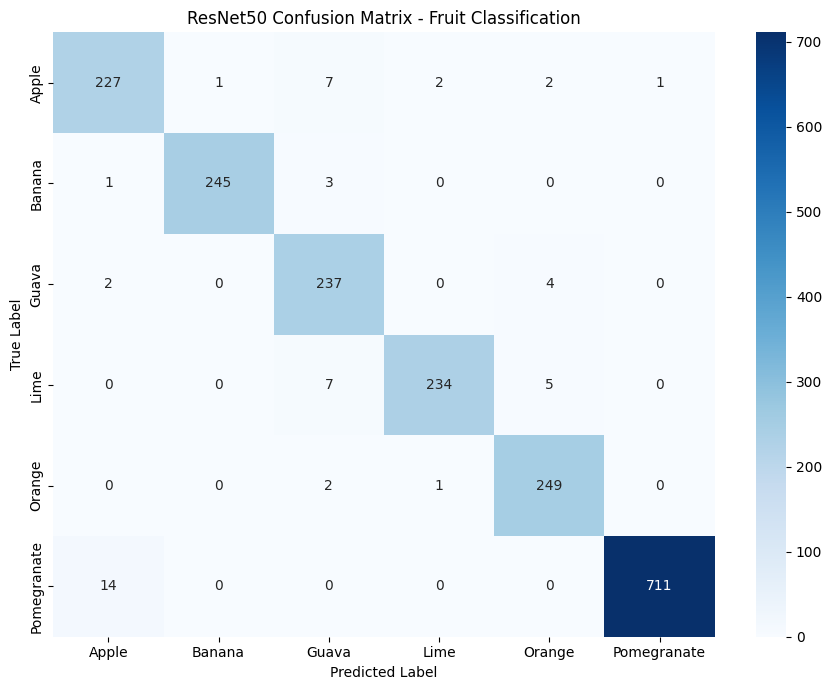

CONFUSION MATRIX SAVED
Location:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/confusion_matrix/resnet50_confusion_matrix.png


In [64]:
# ============================================================
# CELL R24 — CONFUSION MATRIX
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# Create output directory
# ------------------------------------------------------------

CONFUSION_MATRIX_DIR = os.path.join(
    os.path.dirname(CHECKPOINT_DIR),
    "confusion_matrix"
)

os.makedirs(
    CONFUSION_MATRIX_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Calculate confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_true_labels,
    all_pred_labels
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 7)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=fruit_classes,
    yticklabels=fruit_classes
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "ResNet50 Confusion Matrix - Fruit Classification"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

CM_PATH = os.path.join(
    CONFUSION_MATRIX_DIR,
    "resnet50_confusion_matrix.png"
)
plt.savefig(
    CM_PATH,
    dpi=300,
    bbox_inches="tight"
)
plt.show()
print("=" * 70)
print("CONFUSION MATRIX SAVED")
print("=" * 70)
print(
    f"Location:\n{CM_PATH}"
)
print("=" * 70)

In [65]:
# ============================================================
# CELL R25 — CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import (
    classification_report,
    accuracy_score
)

print("=" * 70)
print("RESNET50 CLASSIFICATION REPORT")
print("=" * 70)

report = classification_report(
    all_true_labels,
    all_pred_labels,
    target_names=fruit_classes,
    digits=4
)

print(report)

print("=" * 70)

RESNET50 CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Apple     0.9303    0.9458    0.9380       240
      Banana     0.9959    0.9839    0.9899       249
       Guava     0.9258    0.9753    0.9499       243
        Lime     0.9873    0.9512    0.9689       246
      Orange     0.9577    0.9881    0.9727       252
 Pomegranate     0.9986    0.9807    0.9896       725

    accuracy                         0.9734      1955
   macro avg     0.9659    0.9708    0.9682      1955
weighted avg     0.9741    0.9734    0.9736      1955



In [66]:
# ============================================================
# CELL R26 — SAVE CLASSIFICATION REPORT
# ============================================================

import os

REPORT_DIR = os.path.join(
    os.path.dirname(CHECKPOINT_DIR),
    "metrics"
)

os.makedirs(
    REPORT_DIR,
    exist_ok=True
)

REPORT_PATH = os.path.join(
    REPORT_DIR,
    "resnet50_classification_report.txt"
)

with open(
    REPORT_PATH,
    "w"
) as f:

    f.write(
        "RESNET50 FRUIT CLASSIFICATION\n"
    )

    f.write(
        "=" * 70 + "\n\n"
    )

    f.write(
        f"Test Accuracy: "
        f"{test_accuracy:.4f}%\n\n"
    )

    f.write(
        report
    )
print("=" * 70)
print(
    "Classification report saved:"
)
print(
    REPORT_PATH
)
print("=" * 70)

Classification report saved:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/metrics/resnet50_classification_report.txt


In [67]:
# ============================================================
# CELL R27 — SAVE TEST PREDICTIONS
# ============================================================

import os
import pandas as pd

PREDICTIONS_DIR = os.path.join(
    os.path.dirname(CHECKPOINT_DIR),
    "predictions"
)

os.makedirs(
    PREDICTIONS_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Create prediction DataFrame
# ------------------------------------------------------------

prediction_df = pd.DataFrame({

    "true_label": [
        fruit_classes[i]
        for i in all_true_labels
    ],

    "predicted_label": [
        fruit_classes[i]
        for i in all_pred_labels
    ]
})

# ------------------------------------------------------------
# Correct / incorrect
# ------------------------------------------------------------

prediction_df["correct"] = (
    prediction_df["true_label"]
    ==
    prediction_df["predicted_label"]
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

PREDICTION_PATH = os.path.join(
    PREDICTIONS_DIR,
    "resnet50_test_predictions.csv"
)

prediction_df.to_csv(
    PREDICTION_PATH,
    index=False
)

print("=" * 70)

print(
    f"Predictions saved:\n"
    f"{PREDICTION_PATH}"
)

print(
    f"Correct predictions: "
    f"{prediction_df['correct'].sum()}"
)

print(
    f"Incorrect predictions: "
    f"{(~prediction_df['correct']).sum()}"
)

print("=" * 70)

Predictions saved:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/predictions/resnet50_test_predictions.csv
Correct predictions: 1903
Incorrect predictions: 52


In [68]:
# ============================================================
# CELL R28 — PER-CLASS ACCURACY
# ============================================================

import numpy as np

print("=" * 70)
print("PER-CLASS ACCURACY")
print("=" * 70)

for class_index, class_name in enumerate(fruit_classes):

    # Samples belonging to this class
    class_mask = (
        all_true_labels == class_index
    )

    total = np.sum(class_mask)

    correct = np.sum(
        (
            all_true_labels == class_index
        )
        &
        (
            all_pred_labels == class_index
        )
    )

    if total > 0:

        class_accuracy = (
            correct / total
        ) * 100

    else:

        class_accuracy = 0.0

    print(
        f"{class_name:15s}: "
        f"{class_accuracy:.2f}% "
        f"({correct}/{total})"
    )

print("=" * 70)

PER-CLASS ACCURACY
Apple          : 94.58% (227/240)
Banana         : 98.39% (245/249)
Guava          : 97.53% (237/243)
Lime           : 95.12% (234/246)
Orange         : 98.81% (249/252)
Pomegranate    : 98.07% (711/725)


In [69]:
# ============================================================
# CELL R29 — FINAL RESNET50 RESULT SUMMARY
# ============================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

precision = precision_score(
    all_true_labels,
    all_pred_labels,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_true_labels,
    all_pred_labels,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_true_labels,
    all_pred_labels,
    average="weighted",
    zero_division=0
)

print("=" * 70)
print("FINAL RESNET50 TEST RESULTS")
print("=" * 70)

print(
    f"Accuracy  : {test_accuracy:.2f}%"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1-Score  : {f1:.4f}"
)
print("=" * 70)

FINAL RESNET50 TEST RESULTS
Accuracy  : 97.34%
Precision : 0.9741
Recall    : 0.9734
F1-Score  : 0.9736


In [70]:
model.fc = nn.Linear(model.fc.in_features, 6)

In [71]:
import torch
import torch.nn as nn
from torchvision import models

# --------------------------------------------------
# 1. Load the best fruit classification model
# --------------------------------------------------

quality_model = models.resnet50(
    weights=None
)

# Same 6-class structure as your trained fruit model
quality_model.fc = nn.Linear(
    quality_model.fc.in_features,
    6
)

checkpoint = torch.load(
    BEST_MODEL,
    map_location=device
)

quality_model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("✓ Fruit classification ResNet50 weights loaded")


# --------------------------------------------------
# 2. Replace fruit classification layer
# --------------------------------------------------

num_quality_classes = 3

quality_model.fc = nn.Linear(
    quality_model.fc.in_features,
    num_quality_classes
)

quality_model = quality_model.to(device)

print("✓ Final layer replaced for quality grading")
print("✓ Number of quality classes:", num_quality_classes)

✓ Fruit classification ResNet50 weights loaded
✓ Final layer replaced for quality grading
✓ Number of quality classes: 3


In [72]:
quality_classes = [
    "Good Quality",
    "Bad Quality",
    "Mixed Quality"
]
quality_to_idx = {
    "Good Quality": 0,
    "Bad Quality": 1,
    "Mixed Quality": 2
}
idx_to_quality = {
    0: "Good Quality",
    1: "Bad Quality",
    2: "Mixed Quality"
}
print(quality_classes)

['Good Quality', 'Bad Quality', 'Mixed Quality']


In [73]:
print("Training quality distribution:")
print(train_df["quality"].value_counts())

print("\nValidation quality distribution:")
print(val_df["quality"].value_counts())

print("\nTest quality distribution:")
print(test_df["quality"].value_counts())

Training quality distribution:
quality
Good     8164
Bad      4765
Mixed     753
Name: count, dtype: int64

Validation quality distribution:
quality
Good     2334
Bad      1361
Mixed     214
Name: count, dtype: int64

Test quality distribution:
quality
Good     1166
Bad       682
Mixed     107
Name: count, dtype: int64


In [74]:
print(train_df.columns)
print(train_df.head())

Index(['image_path', 'fruit', 'quality', 'combined_label'], dtype='object')
                                              image_path        fruit quality  \
9694   /content/drive/MyDrive/Fruit Dataset/Good Qual...        Guava    Good   
6210   /content/drive/MyDrive/Fruit Dataset/Bad Quali...        Guava     Bad   
16850  /content/drive/MyDrive/Fruit Dataset/Good Qual...  Pomegranate    Good   
15459  /content/drive/MyDrive/Fruit Dataset/Good Qual...  Pomegranate    Good   
2195   /content/drive/MyDrive/Fruit Dataset/Bad Quali...         Lime     Bad   

         combined_label  
9694         Guava_Good  
6210          Guava_Bad  
16850  Pomegranate_Good  
15459  Pomegranate_Good  
2195           Lime_Bad  


In [75]:
print("Quality classes:", sorted(df["quality"].unique()))
print(df["quality"].value_counts())

Quality classes: ['Bad', 'Good', 'Mixed']
quality
Good     11664
Bad       6808
Mixed     1074
Name: count, dtype: int64


In [76]:
quality_classes = ["Bad", "Good", "Mixed"]

quality_to_idx = {
    name: idx for idx, name in enumerate(quality_classes)
}
print(quality_to_idx)

{'Bad': 0, 'Good': 1, 'Mixed': 2}


In [77]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class QualityDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        label = quality_to_idx[row["quality"]]
        if self.transform:
            image = self.transform(image)
        return image, label

In [78]:
quality_train_dataset = QualityDataset(
    train_df,
    transform=train_transform
)
quality_val_dataset = QualityDataset(
    val_df,
    transform=val_test_transform
)
quality_test_dataset = QualityDataset(
    test_df,
    transform=val_test_transform
)
print("Train:", len(quality_train_dataset))
print("Validation:", len(quality_val_dataset))
print("Test:", len(quality_test_dataset))

Train: 13682
Validation: 3909
Test: 1955


In [79]:
quality_train_loader = DataLoader(
    quality_train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)
quality_val_loader = DataLoader(
    quality_val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)
quality_test_loader = DataLoader(
    quality_test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)
print("Quality DataLoaders created successfully!")

Quality DataLoaders created successfully!


In [80]:
images, labels = next(iter(quality_train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels)

Image batch shape: torch.Size([8, 3, 224, 224])
Label batch shape: torch.Size([8])
Labels: tensor([0, 1, 0, 1, 1, 1, 0, 0])


In [81]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

# --------------------------------------------------
# Quality Model Training Configuration
# --------------------------------------------------

QUALITY_NUM_EPOCHS = 30
QUALITY_LR = 0.01
QUALITY_WEIGHT_DECAY = 1e-2

# Loss function
quality_criterion = nn.CrossEntropyLoss()

# Optimizer
quality_optimizer = optim.AdamW(
    quality_model.parameters(),
    lr=QUALITY_LR,
    weight_decay=QUALITY_WEIGHT_DECAY
)

# Learning-rate scheduler
quality_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    quality_optimizer,
    mode="min",
    factor=0.1,
    patience=3
)
# AMP scaler
quality_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)
print("✓ Quality loss function created")
print("✓ Quality optimizer created")
print("✓ Quality scheduler created")
print("✓ AMP scaler created")

✓ Quality loss function created
✓ Quality optimizer created
✓ Quality scheduler created
✓ AMP scaler created


In [82]:
QUALITY_CHECKPOINT_DIR = os.path.join(
    os.path.dirname(CHECKPOINT_DIR),
    "Quality_ResNet50",
    "checkpoints"
)

QUALITY_METRICS_DIR = os.path.join(
    os.path.dirname(CHECKPOINT_DIR),
    "Quality_ResNet50",
    "metrics"
)

os.makedirs(
    QUALITY_CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    QUALITY_METRICS_DIR,
    exist_ok=True
)

QUALITY_LAST_CHECKPOINT = os.path.join(
    QUALITY_CHECKPOINT_DIR,
    "last_checkpoint.pth"
)

QUALITY_BEST_MODEL = os.path.join(
    QUALITY_CHECKPOINT_DIR,
    "best_model.pth"
)

QUALITY_HISTORY_CSV = os.path.join(
    QUALITY_METRICS_DIR,
    "quality_training_history.csv"
)

print("Quality checkpoint directory:")
print(QUALITY_CHECKPOINT_DIR)

Quality checkpoint directory:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/Quality_ResNet50/checkpoints


In [83]:
quality_history = {
    "epoch": [],
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": []
}

quality_start_epoch = 0
quality_best_val_accuracy = 0.0

print("✓ Quality training history initialized")

✓ Quality training history initialized


In [84]:
if os.path.exists(QUALITY_LAST_CHECKPOINT):

    print("Loading previous quality-training checkpoint...")

    quality_checkpoint = torch.load(
        QUALITY_LAST_CHECKPOINT,
        map_location=device
    )

    quality_model.load_state_dict(
        quality_checkpoint["model_state_dict"]
    )

    quality_optimizer.load_state_dict(
        quality_checkpoint["optimizer_state_dict"]
    )

    quality_scheduler.load_state_dict(
        quality_checkpoint["scheduler_state_dict"]
    )

    # Check if 'scaler_state_dict' exists, is not None, and is not empty
    if (
        "scaler_state_dict" in quality_checkpoint
        and quality_checkpoint["scaler_state_dict"] is not None
        and len(quality_checkpoint["scaler_state_dict"]) > 0
    ):
        quality_scaler.load_state_dict(
            quality_checkpoint["scaler_state_dict"]
        )

    quality_start_epoch = (
        quality_checkpoint["epoch"] + 1
    )

    quality_best_val_accuracy = (
        quality_checkpoint["best_val_accuracy"]
    )

    if "history" in quality_checkpoint:
        quality_history = quality_checkpoint["history"]

    print(
        f"✓ Resuming from epoch "
        f"{quality_start_epoch + 1}"
    )

else:
    print("No previous quality checkpoint found.")
    print("Starting quality training from epoch 1.")

Loading previous quality-training checkpoint...
✓ Resuming from epoch 31


In [85]:
import inspect

print("train_one_epoch:")
print(inspect.signature(train_one_epoch))

print("\nvalidate:")
print(inspect.signature(validate))

train_one_epoch:
(model, loader, criterion, optimizer, device, scaler)

validate:
(model, loader, criterion, device)


In [86]:
from tqdm.auto import tqdm
import torch


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
    scaler
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        loader,
        desc="Training",
        unit="batch",
        leave=True
    )

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        # -----------------------------------------
        # Forward propagation
        # -----------------------------------------

        with torch.amp.autocast(
            device_type=device.type,
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        # -----------------------------------------
        # Backpropagation
        # -----------------------------------------

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        # -----------------------------------------
        # Statistics
        # -----------------------------------------

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        total += labels.size(0)

        # -----------------------------------------
        # Current progress
        # -----------------------------------------

        current_loss = (
            running_loss / total
        )

        current_accuracy = (
            100.0 * correct / total
        )

        progress_bar.set_postfix(
            loss=f"{current_loss:.4f}",
            accuracy=f"{current_accuracy:.2f}%"
        )

    epoch_loss = running_loss / total

    epoch_accuracy = (
        100.0 * correct / total
    )

    return epoch_loss, epoch_accuracy

In [87]:
def validate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        loader,
        desc="Validation",
        unit="batch",
        leave=True
    )

    with torch.no_grad():

        for images, labels in progress_bar:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            total += labels.size(0)

            current_loss = (
                running_loss / total
            )

            current_accuracy = (
                100.0 * correct / total
            )

            progress_bar.set_postfix(
                loss=f"{current_loss:.4f}",
                accuracy=f"{current_accuracy:.2f}%"
            )

    epoch_loss = running_loss / total

    epoch_accuracy = (
        100.0 * correct / total
    )

    return epoch_loss, epoch_accuracy

In [88]:
for epoch in range(
    quality_start_epoch,
    QUALITY_NUM_EPOCHS
):

    print("\n" + "=" * 70)
    print(
        f"QUALITY TRAINING - "
        f"Epoch {epoch + 1}/{QUALITY_NUM_EPOCHS}"
    )
    print("=" * 70)

    train_loss, train_accuracy = train_one_epoch(
        quality_model,
        quality_train_loader,
        quality_criterion,
        quality_optimizer,
        device,
        quality_scaler
    )

    val_loss, val_accuracy = validate(
        quality_model,
        quality_val_loader,
        quality_criterion,
        device
    )

    quality_scheduler.step(val_loss)

    current_lr = quality_optimizer.param_groups[0]["lr"]

    quality_history["epoch"].append(epoch + 1)
    quality_history["train_loss"].append(train_loss)
    quality_history["train_accuracy"].append(train_accuracy)
    quality_history["val_loss"].append(val_loss)
    quality_history["val_accuracy"].append(val_accuracy)
    quality_history["learning_rate"].append(current_lr)

    print(f"Train Loss     : {train_loss:.4f}")
    print(f"Train Accuracy : {train_accuracy:.2f}%")
    print(f"Val Loss       : {val_loss:.4f}")
    print(f"Val Accuracy   : {val_accuracy:.2f}%")
    print(f"Learning Rate  : {current_lr:.8f}")

    is_best = (
        val_accuracy > quality_best_val_accuracy
    )

    if is_best:

        quality_best_val_accuracy = val_accuracy

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    quality_model.state_dict(),
                "val_accuracy":
                    val_accuracy
            },
            QUALITY_BEST_MODEL
        )

        print("✓ New best quality model saved")

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict":
                quality_model.state_dict(),
            "optimizer_state_dict":
                quality_optimizer.state_dict(),
            "scheduler_state_dict":
                quality_scheduler.state_dict(),
            "scaler_state_dict":
                quality_scaler.state_dict(),
            "best_val_accuracy":
                quality_best_val_accuracy,
            "history":
                quality_history
        },
        QUALITY_LAST_CHECKPOINT
    )

    history_df = pd.DataFrame(
        quality_history
    )

    history_df.to_csv(
        QUALITY_HISTORY_CSV,
        index=False
    )

    print("✓ Latest checkpoint saved")

In [89]:
# ============================================================
# Load Best Quality Model
# ============================================================

quality_model = models.resnet50(weights=None)

# Original fruit classification head
quality_model.fc = nn.Linear(
    quality_model.fc.in_features,
    6
)

# Load fruit model structure/weights first
fruit_checkpoint = torch.load(
    BEST_MODEL,
    map_location=device
)

quality_model.load_state_dict(
    fruit_checkpoint["model_state_dict"]
)

# Replace classifier for quality classification
quality_model.fc = nn.Linear(
    quality_model.fc.in_features,
    3
)

# Load the BEST quality model
quality_checkpoint = torch.load(
    QUALITY_BEST_MODEL,
    map_location=device
)

quality_model.load_state_dict(
    quality_checkpoint["model_state_dict"]
)

quality_model = quality_model.to(device)
quality_model.eval()

print("✓ Best Quality ResNet50 model loaded")
print(
    f"Best Validation Accuracy: "
    f"{quality_checkpoint['val_accuracy']:.2f}%"
)

✓ Best Quality ResNet50 model loaded
Best Validation Accuracy: 99.10%


In [90]:
# ============================================================
# Quality Model - Test Set Prediction
# ============================================================

import torch
import numpy as np
from tqdm.auto import tqdm

all_quality_true = []
all_quality_pred = []
all_quality_probs = []

quality_model.eval()

with torch.no_grad():

    for images, labels in tqdm(
        quality_test_loader,
        desc="Testing Quality Model"
    ):

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = quality_model(images)

        # Probability
        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        # Predicted class
        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        # Store results
        all_quality_true.extend(
            labels.cpu().numpy()
        )

        all_quality_pred.extend(
            predictions.cpu().numpy()
        )

        all_quality_probs.extend(
            probabilities.cpu().numpy()
        )

# Convert to NumPy arrays
all_quality_true = np.array(
    all_quality_true
)

all_quality_pred = np.array(
    all_quality_pred
)

all_quality_probs = np.array(
    all_quality_probs
)

print("\n✓ Quality testing completed")

print(
    "Number of test samples:",
    len(all_quality_true)
)

Testing Quality Model:   0%|          | 0/245 [00:00<?, ?it/s]


✓ Quality testing completed
Number of test samples: 1955


In [91]:
# ============================================================
# Quality Test Accuracy
# ============================================================

from sklearn.metrics import accuracy_score

quality_test_accuracy = accuracy_score(
    all_quality_true,
    all_quality_pred
)

print(
    f"Quality Test Accuracy: "
    f"{quality_test_accuracy * 100:.2f}%"
)

Quality Test Accuracy: 98.31%


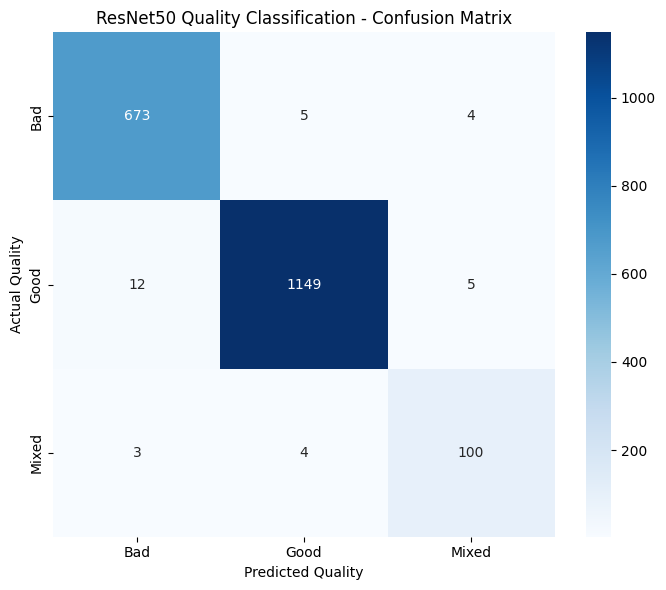

In [92]:
# ============================================================
# Quality Confusion Matrix
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm_quality = confusion_matrix(
    all_quality_true,
    all_quality_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_quality,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=quality_classes,
    yticklabels=quality_classes
)

plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.title("ResNet50 Quality Classification - Confusion Matrix")

plt.tight_layout()
plt.show()

In [93]:
# ============================================================
# Quality Classification Report
# ============================================================

from sklearn.metrics import classification_report

quality_report = classification_report(
    all_quality_true,
    all_quality_pred,
    target_names=quality_classes,
    digits=4
)

print("QUALITY CLASSIFICATION REPORT")
print("=" * 60)
print(quality_report)

QUALITY CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Bad     0.9782    0.9868    0.9825       682
        Good     0.9922    0.9854    0.9888      1166
       Mixed     0.9174    0.9346    0.9259       107

    accuracy                         0.9831      1955
   macro avg     0.9626    0.9689    0.9657      1955
weighted avg     0.9832    0.9831    0.9832      1955



In [94]:
# ============================================================
# Save Quality Classification Report
# ============================================================

quality_report_dict = classification_report(
    all_quality_true,
    all_quality_pred,
    target_names=quality_classes,
    output_dict=True
)

quality_report_df = pd.DataFrame(
    quality_report_dict
).transpose()

QUALITY_REPORT_CSV = os.path.join(
    QUALITY_METRICS_DIR,
    "quality_classification_report.csv"
)

quality_report_df.to_csv(
    QUALITY_REPORT_CSV
)

print("✓ Quality classification report saved:")
print(QUALITY_REPORT_CSV)

✓ Quality classification report saved:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/Quality_ResNet50/metrics/quality_classification_report.csv


In [95]:
# ============================================================
# Per-Class Accuracy
# ============================================================

print("QUALITY PER-CLASS ACCURACY")
print("=" * 50)

for i, class_name in enumerate(quality_classes):

    class_mask = (
        all_quality_true == i
    )

    class_correct = (
        all_quality_pred[class_mask] == i
    ).sum()

    class_total = class_mask.sum()

    class_accuracy = (
        100.0 * class_correct / class_total
    )

    print(
        f"{class_name:10s}: "
        f"{class_accuracy:.2f}% "
        f"({class_correct}/{class_total})"
    )

QUALITY PER-CLASS ACCURACY
Bad       : 98.68% (673/682)
Good      : 98.54% (1149/1166)
Mixed     : 93.46% (100/107)


In [96]:
# ============================================================
# Save Quality Test Predictions
# ============================================================

quality_predictions_df = test_df.reset_index(drop=True).copy()

quality_predictions_df["actual_quality"] = [
    quality_classes[i]
    for i in all_quality_true
]

quality_predictions_df["predicted_quality"] = [
    quality_classes[i]
    for i in all_quality_pred
]

quality_predictions_df["confidence"] = (
    np.max(
        all_quality_probs,
        axis=1
    )
)

QUALITY_PREDICTIONS_CSV = os.path.join(
    QUALITY_METRICS_DIR,
    "quality_test_predictions.csv"
)

quality_predictions_df.to_csv(
    QUALITY_PREDICTIONS_CSV,
    index=False
)

print("✓ Quality test predictions saved:")
print(QUALITY_PREDICTIONS_CSV)

✓ Quality test predictions saved:
/content/drive/MyDrive/Fruit_Classification_Project/ResNet50/Quality_ResNet50/metrics/quality_test_predictions.csv


In [97]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd

from torchvision import models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm.auto import tqdm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load your existing trained ResNet50 model
checkpoint = torch.load(
    BEST_MODEL,
    map_location="cpu",
    weights_only=False
)

trained_resnet = models.resnet50(weights=None)
trained_resnet.fc = nn.Linear(
    trained_resnet.fc.in_features, 6
)

trained_resnet.load_state_dict(
    checkpoint["model_state_dict"]
)

print("Existing ResNet50 checkpoint loaded.")
print("Device:", device)

Existing ResNet50 checkpoint loaded.
Device: cuda


In [98]:
class ChannelAttention(nn.Module):
    def __init__(self, channels=2048, reduction=16):
        super().__init__()

        hidden = max(channels // reduction, 1)

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_features = self.mlp(self.avg_pool(x))
        max_features = self.mlp(self.max_pool(x))

        attention = self.sigmoid(
            avg_features + max_features
        )

        return x * attention


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()

        self.conv = nn.Conv2d(
            2, 1, kernel_size=kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_features = torch.mean(
            x, dim=1, keepdim=True
        )

        max_features = torch.max(
            x, dim=1, keepdim=True
        )[0]

        combined = torch.cat(
            [avg_features, max_features], dim=1
        )

        attention = self.sigmoid(self.conv(combined))

        return x * attention


class CBAM(nn.Module):
    def __init__(self, channels=2048):
        super().__init__()

        self.channel = ChannelAttention(channels)
        self.spatial = SpatialAttention()

    def forward(self, x):
        x = self.channel(x)
        x = self.spatial(x)
        return x

In [99]:
class ResNet50_CBAM_MTL(nn.Module):
    def __init__(
        self,
        trained_resnet,
        num_fruits=6,
        num_qualities=3
    ):
        super().__init__()

        # Reuse trained ResNet50 convolutional layers
        self.backbone = nn.Sequential(
            *list(trained_resnet.children())[:-2]
        )

        # Attention module
        self.cbam = CBAM(channels=2048)

        self.pool = nn.AdaptiveAvgPool2d(1)

        # Fruit classification head
        self.fruit_head = nn.Linear(
            2048, num_fruits
        )

        # Initialize fruit classifier from trained ResNet50
        self.fruit_head.load_state_dict(
            trained_resnet.fc.state_dict()
        )

        # Quality classification head
        self.quality_head = nn.Linear(
            2048, num_qualities
        )

    def forward(self, x):
        features = self.backbone(x)

        features = self.cbam(features)

        features = self.pool(features).flatten(1)

        fruit_logits = self.fruit_head(features)
        quality_logits = self.quality_head(features)

        return fruit_logits, quality_logits

In [100]:
fruit_classes = [
    "Apple", "Banana", "Guava",
    "Lime", "Orange", "Pomegranate"
]

quality_classes = sorted(
    df["quality"].unique().tolist()
)

model = ResNet50_CBAM_MTL(
    trained_resnet=trained_resnet,
    num_fruits=len(fruit_classes),
    num_qualities=len(quality_classes)
).to(device)

print("ResNet50 + CBAM + Multi-task Learning initialized.")
print("Fruit classes:", fruit_classes)
print("Quality classes:", quality_classes)

ResNet50 + CBAM + Multi-task Learning initialized.
Fruit classes: ['Apple', 'Banana', 'Guava', 'Lime', 'Orange', 'Pomegranate']
Quality classes: ['Bad', 'Good', 'Mixed']


In [101]:
fruit_to_idx = {
    name: idx
    for idx, name in enumerate(fruit_classes)
}

quality_to_idx = {
    name: idx
    for idx, name in enumerate(quality_classes)
}


class FruitMTLDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        fruit_label = fruit_to_idx[row["fruit"]]
        quality_label = quality_to_idx[row["quality"]]

        return (
            image,
            torch.tensor(fruit_label, dtype=torch.long),
            torch.tensor(quality_label, dtype=torch.long)
        )


BATCH_SIZE = 8

train_loader_mtl = DataLoader(
    FruitMTLDataset(train_df, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader_mtl = DataLoader(
    FruitMTLDataset(val_df, val_test_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader_mtl = DataLoader(
    FruitMTLDataset(test_df, val_test_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Multi-task data loaders created.")
print("Training batches:", len(train_loader_mtl))
print("Validation batches:", len(val_loader_mtl))
print("Testing batches:", len(test_loader_mtl))

Multi-task data loaders created.
Training batches: 1711
Validation batches: 489
Testing batches: 245


In [102]:
NUM_EPOCHS = 30
LEARNING_RATE = 0.01
WEIGHT_DECAY = 1e-2

fruit_criterion = nn.CrossEntropyLoss()
quality_criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Reduce LR when validation loss stops improving.
# Initial learning rate remains 0.01.
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.1,
    patience=3
)

best_val_loss = float("inf")

SAVE_PATH = os.path.join(
    CHECKPOINT_DIR,
    "resnet50_cbam_mtl_best.pth"
)

LAST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "resnet50_cbam_mtl_last.pth"
)

print("Epochs:", NUM_EPOCHS)
print("Initial learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Best model path:", SAVE_PATH)

Epochs: 30
Initial learning rate: 0.01
Weight decay: 0.01
Best model path: /content/drive/MyDrive/Fruit_Classification_Project/ResNet50/checkpoints/resnet50_cbam_mtl_best.pth


In [103]:
# ============================================================
# RESUME TRAINING FROM LATEST CHECKPOINT
# ============================================================

import os
import torch

CHECKPOINT_DIR = "/content/drive/MyDrive/CBAM_MTL_Checkpoints"

LAST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "last_cbam_mtl_checkpoint.pth"
)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_cbam_mtl_model.pth"
)

HISTORY_PATH = os.path.join(
    CHECKPOINT_DIR,
    "cbam_mtl_history.csv"
)

EPOCH_CHECKPOINT_DIR = os.path.join(
    CHECKPOINT_DIR,
    "epoch_checkpoints"
)

os.makedirs(EPOCH_CHECKPOINT_DIR, exist_ok=True)

NUM_EPOCHS = 30
FIXED_LEARNING_RATE = 0.01

if os.path.isfile(LAST_CHECKPOINT_PATH):

    checkpoint = torch.load(
        LAST_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    # Restore model weights
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    # Restore optimizer state
    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    # Restore the best validation loss
    best_val_loss = checkpoint["best_val_loss"]

    # Resume after the last completed epoch
    start_epoch = checkpoint["epoch"]

    # Restore training history
    history_mtl = checkpoint.get("history", {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "train_combined_accuracy": [],
        "val_combined_accuracy": [],
        "learning_rate": []
    })

    # Keep LR fixed at 0.01, as requested
    for param_group in optimizer.param_groups:
        param_group["lr"] = FIXED_LEARNING_RATE

    print("Checkpoint loaded successfully.")
    print("Last completed epoch:", start_epoch)
    print("Next epoch:", start_epoch + 1)
    print("Best validation loss:", best_val_loss)
    print("Learning rate:", FIXED_LEARNING_RATE)

else:
    raise FileNotFoundError(
        "Latest checkpoint not found: "
        + LAST_CHECKPOINT_PATH
    )

# ============================================================
# IMPORTANT: USE THIS LOOP HEADER IN YOUR TRAINING CODE
# ============================================================

for epoch in range(start_epoch, NUM_EPOCHS):

    epoch_number = epoch + 1

    print(
        f"CBAM + MULTI-TASK TRAINING: "
        f"EPOCH {epoch_number}/{NUM_EPOCHS}"
    )

    # Keep the rest of your existing training-loop body here:
    # 1. Run training and validation
    # 2. Save history
    # 3. Save best model
    # 4. Save latest checkpoint
    # 5. Save the checkpoint for this epoch

Checkpoint loaded successfully.
Last completed epoch: 30
Next epoch: 31
Best validation loss: 0.03689402110500331
Learning rate: 0.01


In [104]:
import os
import torch
import torch.nn as nn
import pandas as pd
from tqdm.auto import tqdm
from google.colab import drive

# ============================================================
# 1. GOOGLE DRIVE AND CHECKPOINT PATHS
# ============================================================

drive.mount("/content/drive")

CHECKPOINT_DIR = "/content/drive/MyDrive/CBAM_MTL_Checkpoints"

EPOCH_CHECKPOINT_DIR = os.path.join(
    CHECKPOINT_DIR, "epoch_checkpoints"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(EPOCH_CHECKPOINT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR, "best_cbam_mtl_model.pth"
)

LAST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR, "last_cbam_mtl_checkpoint.pth"
)

HISTORY_PATH = os.path.join(
    CHECKPOINT_DIR, "cbam_mtl_history.csv"
)

# ============================================================
# 2. CONFIGURATION
# ============================================================

NUM_EPOCHS = 30
FIXED_LEARNING_RATE = 0.01

fruit_criterion = nn.CrossEntropyLoss()
quality_criterion = nn.CrossEntropyLoss()

# Assumes model, optimizer, device, train_loader_mtl,
# val_loader_mtl, fruit_classes, and quality_classes
# have already been defined.

# Set every optimizer parameter group to a constant LR.
# No scheduler is used anywhere in this training loop.
for param_group in optimizer.param_groups:
    param_group["lr"] = FIXED_LEARNING_RATE

best_val_loss = float("inf")

# ============================================================
# 3. TRAINING / VALIDATION FUNCTION
# ============================================================

def run_epoch(loader, training=True):

    model.train(training)

    total_loss = 0.0
    both_correct = 0
    total_samples = 0

    progress = tqdm(
        loader,
        desc="Training" if training else "Validation",
        unit="batch",
        leave=False
    )

    with torch.set_grad_enabled(training):

        for images, fruit_labels, quality_labels in progress:

            images = images.to(device)
            fruit_labels = fruit_labels.to(device)
            quality_labels = quality_labels.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            # Forward propagation
            fruit_logits, quality_logits = model(images)

            # Calculate losses for both tasks
            fruit_loss = fruit_criterion(
                fruit_logits, fruit_labels
            )

            quality_loss = quality_criterion(
                quality_logits, quality_labels
            )

            # Equal weighting of fruit and quality losses
            loss = fruit_loss + quality_loss

            # Backpropagation and optimization
            if training:
                loss.backward()
                optimizer.step()

            # Predictions for both tasks
            fruit_predictions = fruit_logits.argmax(dim=1)
            quality_predictions = quality_logits.argmax(dim=1)

            fruit_matches = fruit_predictions == fruit_labels
            quality_matches = quality_predictions == quality_labels

            # An image is correct only when BOTH predictions match
            both_correct += (
                fruit_matches & quality_matches
            ).sum().item()

            batch_size = images.size(0)
            total_samples += batch_size
            total_loss += loss.item() * batch_size

            progress.set_postfix(
                loss=f"{total_loss / total_samples:.4f}"
            )

    if total_samples == 0:
        raise ValueError("The DataLoader contains no samples.")

    combined_accuracy = (
        100.0 * both_correct / total_samples
    )

    return {
        "loss": total_loss / total_samples,
        "combined_accuracy": combined_accuracy
    }


# ============================================================
# 4. TRAINING HISTORY
# ============================================================

history_mtl = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "train_combined_accuracy": [],
    "val_combined_accuracy": [],
    "learning_rate": []
}

# ============================================================
# 5. TRAINING LOOP
# ============================================================

for epoch in range(start_epoch, NUM_EPOCHS):

    epoch_number = epoch + 1

    print("\n" + "=" * 65)
    print(
        f"CBAM + MULTI-TASK TRAINING: "
        f"EPOCH {epoch_number}/{NUM_EPOCHS}"
    )
    print("=" * 65)

    # ---------------- TRAINING ----------------

    train_metrics = run_epoch(
        train_loader_mtl,
        training=True
    )

    # ---------------- VALIDATION ----------------

    val_metrics = run_epoch(
        val_loader_mtl,
        training=False
    )

    # Keep the learning rate fixed; no scheduler step.
    current_lr = optimizer.param_groups[0]["lr"]

    # ========================================================
    # 6. DISPLAY RESULTS
    # ========================================================

    print(f"\nEpoch: {epoch_number}/{NUM_EPOCHS}")
    print(f"Train Loss: {train_metrics['loss']:.4f}")
    print(f"Validation Loss: {val_metrics['loss']:.4f}")

    print(
        f"Train Combined Accuracy: "
        f"{train_metrics['combined_accuracy']:.2f}%"
    )

    print(
        f"Validation Combined Accuracy: "
        f"{val_metrics['combined_accuracy']:.2f}%"
    )

    print(f"Learning Rate: {current_lr:.8f}")

    # ========================================================
    # 7. SAVE HISTORY
    # ========================================================

    history_mtl["epoch"].append(epoch_number)
    history_mtl["train_loss"].append(train_metrics["loss"])
    history_mtl["val_loss"].append(val_metrics["loss"])

    history_mtl["train_combined_accuracy"].append(
        train_metrics["combined_accuracy"]
    )

    history_mtl["val_combined_accuracy"].append(
        val_metrics["combined_accuracy"]
    )

    history_mtl["learning_rate"].append(current_lr)

    pd.DataFrame(history_mtl).to_csv(
        HISTORY_PATH,
        index=False
    )

    # ========================================================
    # 8. SAVE BEST MODEL
    # ========================================================

    if val_metrics["loss"] < best_val_loss:

        best_val_loss = val_metrics["loss"]

        best_checkpoint = {
            "epoch": epoch_number,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "current_val_loss": val_metrics["loss"],
            "learning_rate": current_lr,
            "train_metrics": train_metrics,
            "val_metrics": val_metrics,
            "fruit_classes": fruit_classes,
            "quality_classes": quality_classes,
            "history": history_mtl
        }

        torch.save(
            best_checkpoint,
            BEST_MODEL_PATH
        )

        print("Best model saved: best_cbam_mtl_model.pth")

    # ========================================================
    # 9. SAVE LATEST CHECKPOINT
    # ========================================================

    latest_checkpoint = {
        "epoch": epoch_number,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "current_val_loss": val_metrics["loss"],
        "learning_rate": current_lr,
        "train_metrics": train_metrics,
        "val_metrics": val_metrics,
        "fruit_classes": fruit_classes,
        "quality_classes": quality_classes,
        "history": history_mtl
    }

    torch.save(
        latest_checkpoint,
        LAST_CHECKPOINT_PATH
    )

    print("Latest checkpoint saved: last_cbam_mtl_checkpoint.pth")

    # ========================================================
    # 10. SAVE CHECKPOINT FOR EVERY EPOCH
    # ========================================================

    epoch_checkpoint_path = os.path.join(
        EPOCH_CHECKPOINT_DIR,
        f"checkpoint_epoch_{epoch_number}.pth"
    )

    epoch_checkpoint = {
        "epoch": epoch_number,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "current_val_loss": val_metrics["loss"],
        "learning_rate": current_lr,
        "train_metrics": train_metrics,
        "val_metrics": val_metrics,
        "fruit_classes": fruit_classes,
        "quality_classes": quality_classes,
        "history": history_mtl
    }

    torch.save(
        epoch_checkpoint,
        epoch_checkpoint_path
    )

    print(
        f"Epoch checkpoint saved: "
        f"checkpoint_epoch_{epoch_number}.pth"
    )

    print("History saved: cbam_mtl_history.csv")


# ============================================================
# 11. VERIFY SAVED FILES
# ============================================================

print("\n" + "=" * 65)
print("CBAM + MULTI-TASK TRAINING COMPLETED")
print("=" * 65)

print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Fixed learning rate: {FIXED_LEARNING_RATE:.8f}")

for path in [
    BEST_MODEL_PATH,
    LAST_CHECKPOINT_PATH,
    HISTORY_PATH
]:
    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 ** 2)

        print(
            f"Verified: {os.path.basename(path)} "
            f"({size_mb:.2f} MB)"
        )
    else:
        print(f"WARNING: File not found: {path}")

saved_epoch_files = [
    name for name in os.listdir(EPOCH_CHECKPOINT_DIR)
    if name.startswith("checkpoint_epoch_")
    and name.endswith(".pth")
]

print(f"Epoch checkpoint files found: {len(saved_epoch_files)}")
print("Epoch checkpoint folder:", EPOCH_CHECKPOINT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

CBAM + MULTI-TASK TRAINING COMPLETED
Best validation loss: inf
Fixed learning rate: 0.01000000
Verified: best_cbam_mtl_model.pth (275.69 MB)
Verified: last_cbam_mtl_checkpoint.pth (275.70 MB)
Verified: cbam_mtl_history.csv (0.00 MB)
Epoch checkpoint files found: 30
Epoch checkpoint folder: /content/drive/MyDrive/CBAM_MTL_Checkpoints/epoch_checkpoints


CBAM + MULTI-TASK MODEL TESTING
Device: cuda
Best checkpoint: /content/drive/MyDrive/CBAM_MTL_Checkpoints/best_cbam_mtl_model.pth
Best checkpoint epoch: 11
Fruit classes: ['Apple', 'Banana', 'Guava', 'Lime', 'Orange', 'Pomegranate']
Quality classes: ['Bad', 'Good', 'Mixed']
Test batches: 245


Testing CBAM + MTL:   0%|          | 0/245 [00:00<?, ?it/s]


FINAL TEST RESULTS
Total test images: 1955
Test loss: 0.0566

FRUIT CLASSIFICATION
Accuracy : 99.49%
Precision: 0.9932
Recall   : 0.9941
F1-score : 0.9937

QUALITY CLASSIFICATION
Accuracy : 98.52%
Precision: 0.9431
Recall   : 0.9875
F1-score : 0.9632

JOINT MULTI-TASK PERFORMANCE
Combined accuracy: 98.06%

FRUIT CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Apple       0.99      0.99      0.99       240
      Banana       1.00      1.00      1.00       249
       Guava       0.99      0.99      0.99       243
        Lime       1.00      0.99      0.99       246
      Orange       0.98      0.99      0.99       252
 Pomegranate       1.00      1.00      1.00       725

    accuracy                           0.99      1955
   macro avg       0.99      0.99      0.99      1955
weighted avg       0.99      0.99      0.99      1955


QUALITY CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Bad       0.99      0.99 

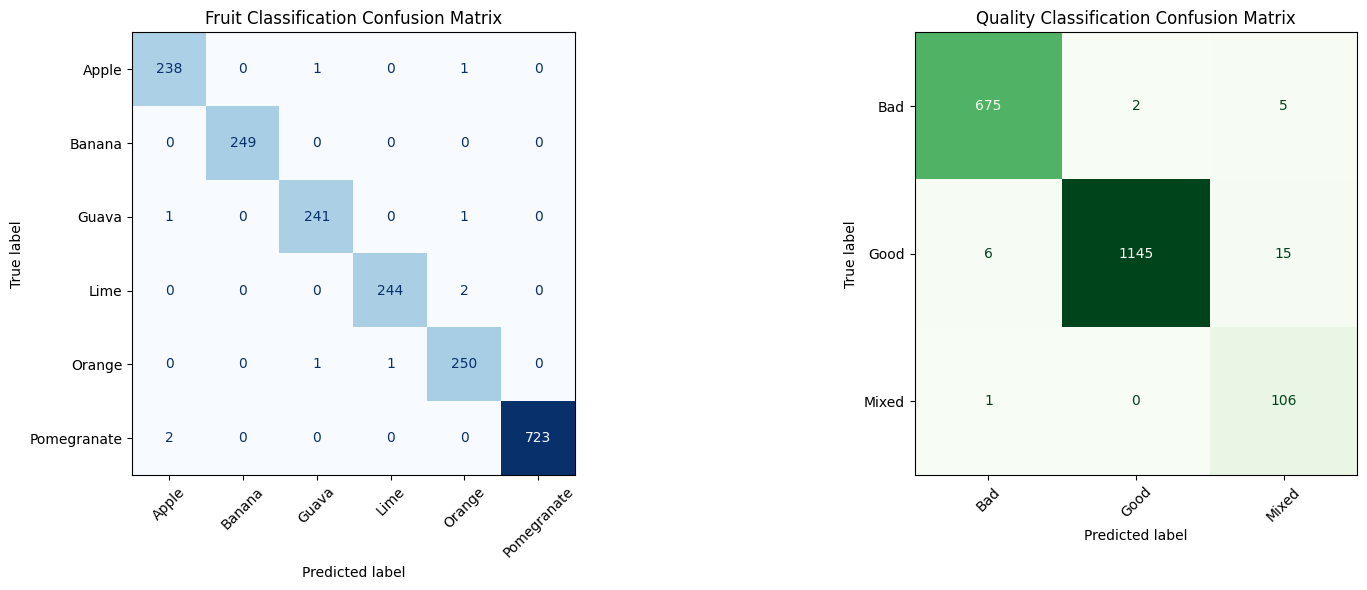


Testing completed successfully.
Results saved in: /content/drive/MyDrive/CBAM_MTL_Checkpoints/testing_results
 - test_predictions.csv
 - test_metrics.csv


In [105]:

# ============================================================
# TESTING: RESNET50 + CBAM + MULTI-TASK LEARNING
# ============================================================

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. CHECK DEVICE AND LOAD THE BEST TRAINED MODEL
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CHECKPOINT_DIR = "/content/drive/MyDrive/CBAM_MTL_Checkpoints"

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_cbam_mtl_model.pth"
)

if not os.path.isfile(BEST_MODEL_PATH):
    raise FileNotFoundError(
        f"Best model checkpoint not found: {BEST_MODEL_PATH}"
    )

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

# Restore the exact class ordering used during training.
fruit_classes = checkpoint.get(
    "fruit_classes", fruit_classes
)

quality_classes = checkpoint.get(
    "quality_classes", quality_classes
)

# Load trained weights into the existing model architecture.
model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print("=" * 60)
print("CBAM + MULTI-TASK MODEL TESTING")
print("=" * 60)
print("Device:", device)
print("Best checkpoint:", BEST_MODEL_PATH)
print("Best checkpoint epoch:", checkpoint.get("epoch", "Unknown"))
print("Fruit classes:", fruit_classes)
print("Quality classes:", quality_classes)
print("Test batches:", len(test_loader_mtl))

# ------------------------------------------------------------
# 2. PREDICT ON THE COMPLETE TEST DATASET
# ------------------------------------------------------------

true_fruits = []
predicted_fruits = []

true_qualities = []
predicted_qualities = []

fruit_probabilities = []
quality_probabilities = []

total_test_loss = 0.0
total_samples = 0

fruit_criterion = torch.nn.CrossEntropyLoss()
quality_criterion = torch.nn.CrossEntropyLoss()

with torch.inference_mode():

    for images, fruit_labels, quality_labels in tqdm(
        test_loader_mtl,
        desc="Testing CBAM + MTL"
    ):

        images = images.to(device)
        fruit_labels = fruit_labels.to(device)
        quality_labels = quality_labels.to(device)

        # Forward pass through both task heads.
        fruit_logits, quality_logits = model(images)

        # Calculate test loss for both tasks.
        fruit_loss = fruit_criterion(
            fruit_logits, fruit_labels
        )

        quality_loss = quality_criterion(
            quality_logits, quality_labels
        )

        loss = fruit_loss + quality_loss

        batch_size = images.size(0)
        total_test_loss += loss.item() * batch_size
        total_samples += batch_size

        # Convert logits to probabilities.
        fruit_probs = torch.softmax(
            fruit_logits, dim=1
        )

        quality_probs = torch.softmax(
            quality_logits, dim=1
        )

        # Select the most probable class.
        fruit_preds = fruit_logits.argmax(dim=1)
        quality_preds = quality_logits.argmax(dim=1)

        # Store actual and predicted labels.
        true_fruits.extend(
            fruit_labels.cpu().numpy().tolist()
        )

        predicted_fruits.extend(
            fruit_preds.cpu().numpy().tolist()
        )

        true_qualities.extend(
            quality_labels.cpu().numpy().tolist()
        )

        predicted_qualities.extend(
            quality_preds.cpu().numpy().tolist()
        )

        fruit_probabilities.extend(
            fruit_probs.cpu().numpy().tolist()
        )

        quality_probabilities.extend(
            quality_probs.cpu().numpy().tolist()
        )

# Convert predictions to NumPy arrays.
true_fruits = np.asarray(true_fruits)
predicted_fruits = np.asarray(predicted_fruits)

true_qualities = np.asarray(true_qualities)
predicted_qualities = np.asarray(predicted_qualities)

fruit_probabilities = np.asarray(fruit_probabilities)
quality_probabilities = np.asarray(quality_probabilities)

if total_samples == 0:
    raise ValueError("The test DataLoader contains no samples.")

# ------------------------------------------------------------
# 3. CALCULATE TEST METRICS
# ------------------------------------------------------------

fruit_accuracy = accuracy_score(
    true_fruits, predicted_fruits
) * 100

quality_accuracy = accuracy_score(
    true_qualities, predicted_qualities
) * 100

# Both predictions must be correct for a jointly correct image.
combined_accuracy = np.mean(
    (true_fruits == predicted_fruits) &
    (true_qualities == predicted_qualities)
) * 100

average_test_loss = total_test_loss / total_samples

fruit_precision = precision_score(
    true_fruits, predicted_fruits,
    average="macro", zero_division=0
)

fruit_recall = recall_score(
    true_fruits, predicted_fruits,
    average="macro", zero_division=0
)

fruit_f1 = f1_score(
    true_fruits, predicted_fruits,
    average="macro", zero_division=0
)

quality_precision = precision_score(
    true_qualities, predicted_qualities,
    average="macro", zero_division=0
)

quality_recall = recall_score(
    true_qualities, predicted_qualities,
    average="macro", zero_division=0
)

quality_f1 = f1_score(
    true_qualities, predicted_qualities,
    average="macro", zero_division=0
)

# ------------------------------------------------------------
# 4. DISPLAY TEST RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print("Total test images:", total_samples)
print(f"Test loss: {average_test_loss:.4f}")

print("\nFRUIT CLASSIFICATION")
print(f"Accuracy : {fruit_accuracy:.2f}%")
print(f"Precision: {fruit_precision:.4f}")
print(f"Recall   : {fruit_recall:.4f}")
print(f"F1-score : {fruit_f1:.4f}")

print("\nQUALITY CLASSIFICATION")
print(f"Accuracy : {quality_accuracy:.2f}%")
print(f"Precision: {quality_precision:.4f}")
print(f"Recall   : {quality_recall:.4f}")
print(f"F1-score : {quality_f1:.4f}")

print("\nJOINT MULTI-TASK PERFORMANCE")
print(
    f"Combined accuracy: {combined_accuracy:.2f}%"
)

print("\nFRUIT CLASSIFICATION REPORT")
print(classification_report(
    true_fruits,
    predicted_fruits,
    labels=list(range(len(fruit_classes))),
    target_names=fruit_classes,
    zero_division=0
))

print("\nQUALITY CLASSIFICATION REPORT")
print(classification_report(
    true_qualities,
    predicted_qualities,
    labels=list(range(len(quality_classes))),
    target_names=[str(q) for q in quality_classes],
    zero_division=0
))

# ------------------------------------------------------------
# 5. CONFUSION MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

fruit_cm = confusion_matrix(
    true_fruits,
    predicted_fruits,
    labels=list(range(len(fruit_classes)))
)

quality_cm = confusion_matrix(
    true_qualities,
    predicted_qualities,
    labels=list(range(len(quality_classes)))
)

ConfusionMatrixDisplay(
    confusion_matrix=fruit_cm,
    display_labels=fruit_classes
).plot(
    ax=axes[0],
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

axes[0].set_title("Fruit Classification Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix=quality_cm,
    display_labels=quality_classes
).plot(
    ax=axes[1],
    cmap="Greens",
    xticks_rotation=45,
    colorbar=False
)

axes[1].set_title("Quality Classification Confusion Matrix")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. SAVE TEST PREDICTIONS AND METRICS
# ------------------------------------------------------------

os.makedirs(
    os.path.join(CHECKPOINT_DIR, "testing_results"),
    exist_ok=True
)

RESULTS_DIR = os.path.join(
    CHECKPOINT_DIR, "testing_results"
)

test_results_df = pd.DataFrame({
    "actual_fruit": [
        fruit_classes[i] for i in true_fruits
    ],
    "predicted_fruit": [
        fruit_classes[i] for i in predicted_fruits
    ],
    "actual_quality": [
        quality_classes[i] for i in true_qualities
    ],
    "predicted_quality": [
        quality_classes[i] for i in predicted_qualities
    ],
    "fruit_correct": (
        true_fruits == predicted_fruits
    ),
    "quality_correct": (
        true_qualities == predicted_qualities
    )
})

test_results_df.to_csv(
    os.path.join(RESULTS_DIR, "test_predictions.csv"),
    index=False
)

metrics_df = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Fruit Accuracy (%)",
        "Fruit Macro Precision",
        "Fruit Macro Recall",
        "Fruit Macro F1",
        "Quality Accuracy (%)",
        "Quality Macro Precision",
        "Quality Macro Recall",
        "Quality Macro F1",
        "Combined Accuracy (%)"
    ],
    "Value": [
        average_test_loss,
        fruit_accuracy,
        fruit_precision,
        fruit_recall,
        fruit_f1,
        quality_accuracy,
        quality_precision,
        quality_recall,
        quality_f1,
        combined_accuracy
    ]
})

metrics_df.to_csv(
    os.path.join(RESULTS_DIR, "test_metrics.csv"),
    index=False
)

print("\nTesting completed successfully.")
print("Results saved in:", RESULTS_DIR)
print(" - test_predictions.csv")
print(" - test_metrics.csv")


Device: cuda


Saving IMG_0112.JPG to IMG_0112.JPG
Uploaded image: IMG_0112.JPG


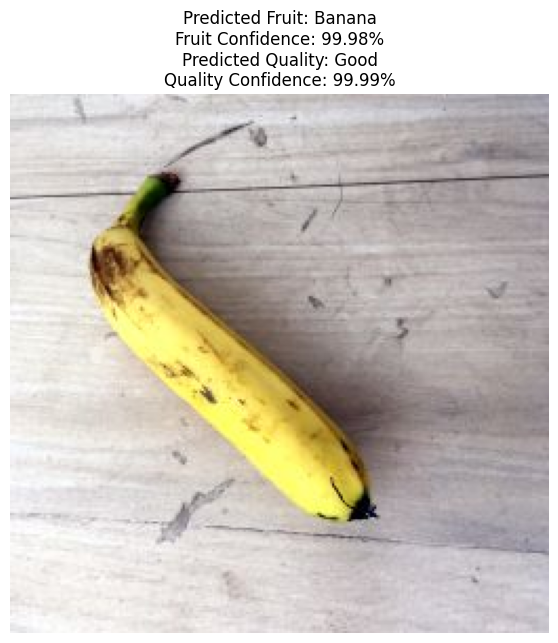

CBAM + MULTI-TASK PREDICTION RESULTS
Image: IMG_0112.JPG
Predicted fruit: Banana
Fruit confidence: 99.98%
Predicted quality: Good
Quality confidence: 99.99%

Fruit class probabilities:
Apple: 0.02%
Banana: 99.98%
Guava: 0.00%
Lime: 0.00%
Orange: 0.00%
Pomegranate: 0.00%

Quality class probabilities:
Bad: 0.00%
Good: 99.99%
Mixed: 0.01%


In [106]:

# ============================================================
# SINGLE IMAGE PREDICTION - RESNET50 + CBAM + MULTI-TASK
# ============================================================

import os
import io
import torch
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

# ------------------------------------------------------------
# 1. SET DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ------------------------------------------------------------
# 2. UPLOAD A FRUIT IMAGE
# ------------------------------------------------------------

uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded. Please upload a fruit image.")

image_filename = next(iter(uploaded))

image = Image.open(
    io.BytesIO(uploaded[image_filename])
).convert("RGB")

print("Uploaded image:", image_filename)

# ------------------------------------------------------------
# 3. LOAD THE TRAINED MODEL CHECKPOINT
# ------------------------------------------------------------

CHECKPOINT_PATH = (
    "/content/drive/MyDrive/CBAM_MTL_Checkpoints/"
    "best_cbam_mtl_model.pth"
)

if not os.path.isfile(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}\n"
        "Mount Google Drive and verify the checkpoint location."
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

# Use the model architecture defined in your notebook.
# Run the cells defining CBAM and the ResNet50 MTL model first.
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

# Restore the original class ordering.
fruit_classes = checkpoint.get(
    "fruit_classes", fruit_classes
)

quality_classes = checkpoint.get(
    "quality_classes", quality_classes
)

# ------------------------------------------------------------
# 4. PREPROCESS IMAGE
# ------------------------------------------------------------

# Use exactly the same transform as your validation/test dataset.
input_tensor = val_test_transform(image)

# Shape: [C, H, W] -> [1, C, H, W]
input_tensor = input_tensor.unsqueeze(0).to(device)

# ------------------------------------------------------------
# 5. PREDICT FRUIT AND QUALITY
# ------------------------------------------------------------

with torch.inference_mode():

    fruit_logits, quality_logits = model(input_tensor)

    fruit_probs = torch.softmax(
        fruit_logits, dim=1
    )[0]

    quality_probs = torch.softmax(
        quality_logits, dim=1
    )[0]

    fruit_index = fruit_probs.argmax().item()
    quality_index = quality_probs.argmax().item()

    predicted_fruit = fruit_classes[fruit_index]
    predicted_quality = quality_classes[quality_index]

    fruit_confidence = (
        fruit_probs[fruit_index].item() * 100
    )

    quality_confidence = (
        quality_probs[quality_index].item() * 100
    )

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis("off")

plt.title(
    f"Predicted Fruit: {predicted_fruit}\n"
    f"Fruit Confidence: {fruit_confidence:.2f}%\n"
    f"Predicted Quality: {predicted_quality}\n"
    f"Quality Confidence: {quality_confidence:.2f}%"
)

plt.show()

print("=" * 50)
print("CBAM + MULTI-TASK PREDICTION RESULTS")
print("=" * 50)
print("Image:", image_filename)
print("Predicted fruit:", predicted_fruit)
print(f"Fruit confidence: {fruit_confidence:.2f}%")
print("Predicted quality:", predicted_quality)
print(f"Quality confidence: {quality_confidence:.2f}%")

# ------------------------------------------------------------
# 7. DISPLAY ALL CLASS PROBABILITIES
# ------------------------------------------------------------

print("\nFruit class probabilities:")
for name, prob in zip(
    fruit_classes, fruit_probs.cpu().tolist()
):
    print(f"{name}: {prob * 100:.2f}%")

print("\nQuality class probabilities:")
for name, prob in zip(
    quality_classes, quality_probs.cpu().tolist()
):
    print(f"{name}: {prob * 100:.2f}%")


Trained CBAM + MTL model loaded.
Device: cuda
Grad-CAM target layer: backbone[-1][-1] (Layer 4)


Saving IMG_20190902_102406.jpg to IMG_20190902_102406.jpg


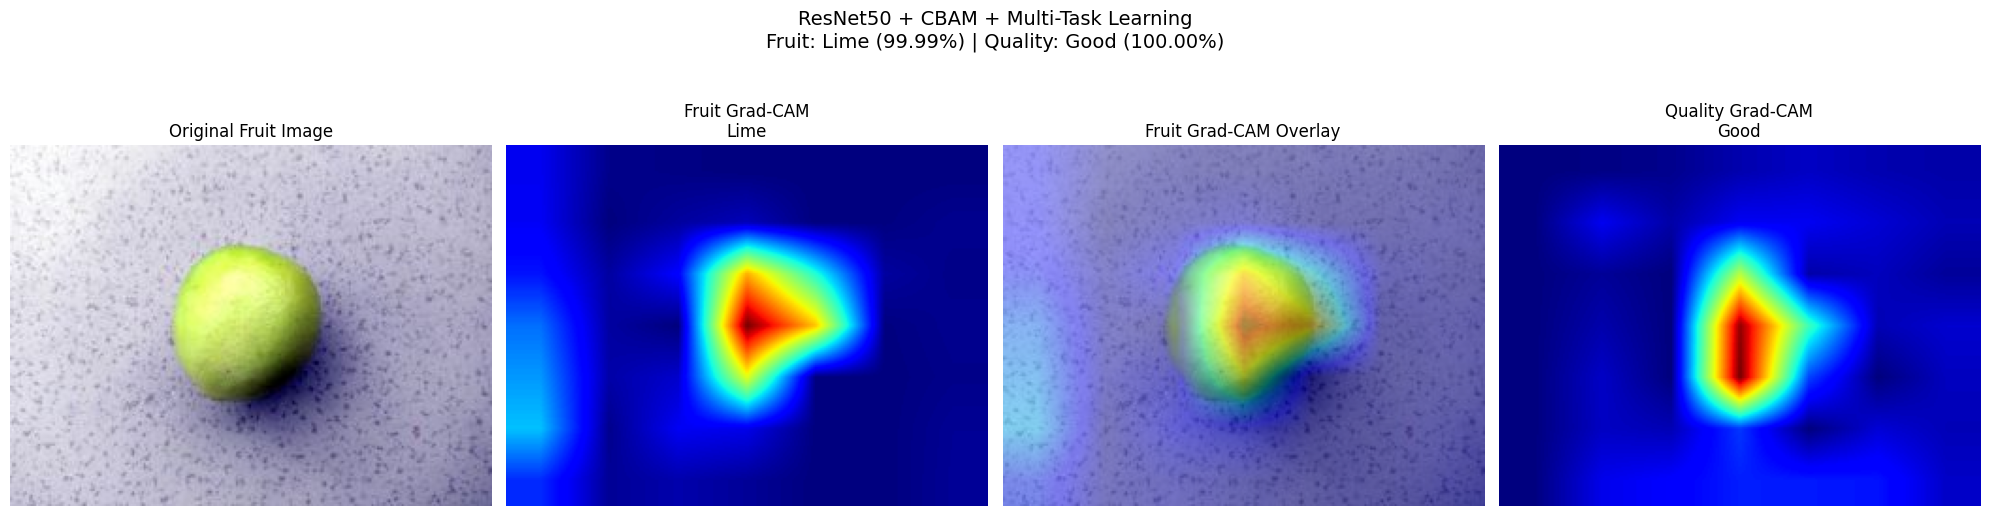


GRAD-CAM PREDICTION RESULTS
Image: IMG_20190902_102406.jpg
Predicted fruit: Lime
Fruit confidence: 99.99%
Predicted quality: Good
Quality confidence: 100.00%

Grad-CAM files saved to: /content/drive/MyDrive/CBAM_MTL_Checkpoints/gradcam_visualizations


In [107]:
# ============================================================
# GRAD-CAM FOR RESNET50 + CBAM + MULTI-TASK LEARNING
# Fruit Classification + Fruit Quality Grading
# =============================================================

import os
import io
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torchvision.transforms as T
from torchvision import models
from PIL import Image
from google.colab import files
from torch.nn import functional as F

# ------------------------------------------------------------
# 1. ARCHITECTURE DEFINITIONS (To prevent NameError)
# ------------------------------------------------------------

class ChannelAttention(nn.Module):
    def __init__(self, channels=2048, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 1)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_features = self.mlp(self.avg_pool(x))
        max_features = self.mlp(self.max_pool(x))
        attention = self.sigmoid(avg_features + max_features)
        return x * attention


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(
            2, 1, kernel_size=kernel_size,
            padding=kernel_size // 2,
            bias=False
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_features = torch.mean(x, dim=1, keepdim=True)
        max_features = torch.max(x, dim=1, keepdim=True)[0]
        combined = torch.cat([avg_features, max_features], dim=1)
        attention = self.sigmoid(self.conv(combined))
        return x * attention


class CBAM(nn.Module):
    def __init__(self, channels=2048):
        super().__init__()
        self.channel = ChannelAttention(channels)
        self.spatial = SpatialAttention()

    def forward(self, x):
        x = self.channel(x)
        x = self.spatial(x)
        return x


class ResNet50_CBAM_MTL(nn.Module):
    def __init__(self, num_fruits=6, num_qualities=3):
        super().__init__()
        resnet = models.resnet50(weights=None)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])
        self.cbam = CBAM(channels=2048)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fruit_head = nn.Linear(2048, num_fruits)
        self.quality_head = nn.Linear(2048, num_qualities)

    def forward(self, x):
        features = self.backbone(x)
        features = self.cbam(features)
        features = self.pool(features).flatten(1)
        fruit_logits = self.fruit_head(features)
        quality_logits = self.quality_head(features)
        return fruit_logits, quality_logits

# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CHECKPOINT_PATH = (
    "/content/drive/MyDrive/CBAM_MTL_Checkpoints/"
    "best_cbam_mtl_model.pth"
)

if not os.path.isfile(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}\n"
        "Check your Google Drive path."
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

# Restore the classes metadata
fruit_classes = checkpoint.get(
    "fruit_classes", ["Apple", "Banana", "Guava", "Lime", "Orange", "Pomegranate"]
)

quality_classes = checkpoint.get(
    "quality_classes", ["Bad", "Good", "Mixed"]
)

# Instantiate and load model weights
resnet_model = ResNet50_CBAM_MTL(
    num_fruits=len(fruit_classes),
    num_qualities=len(quality_classes)
)

resnet_model.load_state_dict(checkpoint["model_state_dict"])
resnet_model = resnet_model.to(device)
resnet_model.eval()

print("Trained CBAM + MTL model loaded.")
print("Device:", device)

# ------------------------------------------------------------
# 3. FIND THE LAST RESNET50 CONVOLUTIONAL BLOCK
# ------------------------------------------------------------

def find_last_resnet_layer(model_obj):
    if hasattr(model_obj, 'backbone') and isinstance(model_obj.backbone, torch.nn.Sequential):
        try:
            print("Grad-CAM target layer: backbone[-1][-1] (Layer 4)")
            return model_obj.backbone[-1][-1]
        except Exception:
            pass
    raise RuntimeError("Could not automatically locate ResNet50 layer4.")

target_layer = find_last_resnet_layer(resnet_model)

# ------------------------------------------------------------
# 4. UPLOAD ONE FRUIT IMAGE
# ------------------------------------------------------------

uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload a fruit image.")

image_filename = next(iter(uploaded))

original_image = Image.open(
    io.BytesIO(uploaded[image_filename])
).convert("RGB")

# Defined validation transform locally for self-containment
val_test_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

input_tensor = val_test_transform(
    original_image
).unsqueeze(0).to(device)

# ------------------------------------------------------------
# 5. CAPTURE FEATURE MAPS FOR GRAD-CAM
# ------------------------------------------------------------

captured = {}

def activation_hook(module, inputs, output):
    captured["activation"] = output

hook = target_layer.register_forward_hook(activation_hook)

try:
    resnet_model.zero_grad(set_to_none=True)

    with torch.enable_grad():
        input_tensor = input_tensor.detach()
        fruit_logits, quality_logits = resnet_model(input_tensor)

        if "activation" not in captured:
            raise RuntimeError(
                "Target layer activations were not captured."
            )

        activations = captured["activation"]
        fruit_index = fruit_logits[0].argmax().item()
        quality_index = quality_logits[0].argmax().item()

        fruit_gradients = torch.autograd.grad(
            outputs=fruit_logits[0, fruit_index],
            inputs=activations,
            retain_graph=True
        )[0]

        quality_gradients = torch.autograd.grad(
            outputs=quality_logits[0, quality_index],
            inputs=activations
        )[0]

        activations_saved = activations.detach().clone()
        fruit_gradients = fruit_gradients.detach()
        quality_gradients = quality_gradients.detach()

        fruit_probs = torch.softmax(resnet_model(input_tensor)[0].detach(), dim=1)[0]
        quality_probs = torch.softmax(resnet_model(input_tensor)[1].detach(), dim=1)[0]

finally:
    hook.remove()

# ------------------------------------------------------------
# 6. GENERATE GRAD-CAM MAP
# ------------------------------------------------------------

def generate_gradcam(activations, gradients, output_size):
    weights = gradients.mean(dim=(2, 3), keepdim=True)
    cam = (weights * activations).sum(dim=1, keepdim=True)
    cam = F.relu(cam)
    cam = F.interpolate(
        cam,
        size=output_size,
        mode="bilinear",
        align_corners=False
    )
    cam = cam[0, 0].cpu().numpy()
    cam_min = cam.min()
    cam_max = cam.max()
    if cam_max - cam_min > 1e-8:
        cam = (cam - cam_min) / (cam_max - cam_min)
    else:
        cam = np.zeros_like(cam)
    return cam

height, width = np.asarray(original_image).shape[:2]

fruit_cam = generate_gradcam(
    activations_saved,
    fruit_gradients,
    (height, width)
)

quality_cam = generate_gradcam(
    activations_saved,
    quality_gradients,
    (height, width)
)

# ------------------------------------------------------------
# 7. GENERATE COLORED OVERLAYS
# ------------------------------------------------------------

image_array = np.asarray(original_image).astype(np.float32)

def make_overlay(image_array, cam, alpha=0.40):
    heatmap = plt.get_cmap("jet")(cam)[..., :3] * 255
    blended = (
        (1 - alpha) * image_array
        + alpha * heatmap
    )
    return np.clip(blended, 0, 255).astype(np.uint8)

fruit_overlay = make_overlay(image_array, fruit_cam)
quality_overlay = make_overlay(image_array, quality_cam)

# ------------------------------------------------------------
# 8. DISPLAY GRAD-CAM RESULTS
# ------------------------------------------------------------

predicted_fruit = fruit_classes[fruit_index]
predicted_quality = quality_classes[quality_index]

fruit_confidence = fruit_probs[fruit_index].item() * 100
quality_confidence = quality_probs[quality_index].item() * 100

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

axes[0].imshow(original_image)
axes[0].set_title("Original Fruit Image")

axes[1].imshow(fruit_cam, cmap="jet", vmin=0, vmax=1)
axes[1].set_title(f"Fruit Grad-CAM\n{predicted_fruit}")

axes[2].imshow(fruit_overlay)
axes[2].set_title("Fruit Grad-CAM Overlay")

axes[3].imshow(quality_cam, cmap="jet", vmin=0, vmax=1)
axes[3].set_title(f"Quality Grad-CAM\n{predicted_quality}")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    "ResNet50 + CBAM + Multi-Task Learning\n" +
    f"Fruit: {predicted_fruit} ({fruit_confidence:.2f}%) | " +
    f"Quality: {predicted_quality} ({quality_confidence:.2f}%)",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. PRINT PREDICTION RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("GRAD-CAM PREDICTION RESULTS")
print("=" * 60)

print("Image:", image_filename)
print("Predicted fruit:", predicted_fruit)
print(f"Fruit confidence: {fruit_confidence:.2f}%")
print("Predicted quality:", predicted_quality)
print(f"Quality confidence: {quality_confidence:.2f}%")

# ------------------------------------------------------------
# 10. SAVE GRAD-CAM VISUALIZATIONS
# ------------------------------------------------------------

OUTPUT_DIR = (
    "/content/drive/MyDrive/CBAM_MTL_Checkpoints/"
    "gradcam_visualizations"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

Image.fromarray(fruit_overlay).save(
    os.path.join(OUTPUT_DIR, "fruit_gradcam_overlay.png")
)

Image.fromarray(quality_overlay).save(
    os.path.join(OUTPUT_DIR, "quality_gradcam_overlay.png")
)

print("\nGrad-CAM files saved to:", OUTPUT_DIR)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 81.4 MB/s eta 0:00:00
Inference device: cuda:0
ResNet50 + CBAM + MTL checkpoint loaded successfully.
Loading Qwen. This may take a few minutes...


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Qwen loaded successfully.


Saving IMG_20190902_102406.jpg to IMG_20190902_102406 (1).jpg


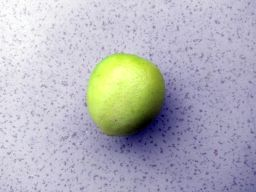

Image: IMG_20190902_102406 (1).jpg

========== TRAINED MODEL RESULTS ==========
Fruit: Lime
Fruit confidence: 99.99%
Quality: Good
Quality confidence: 100.00%

========== QWEN VISUAL EXPLANATION ==========
{
  "model_fruit_prediction": "Lime",
  "model_fruit_confidence": "99.99%",
  "model_quality_prediction": "Good",
  "model_quality_confidence": "100.00%",
  "visual_evidence": "A single lime with a smooth, green surface and a round shape.",
  "limitations": "The image is clear but lacks context for determining the freshness or ripeness of the lime.",
  "summary": "The image shows a lime with a high confidence prediction from the model."
}

Results saved to: /content/fruitai_prediction.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [108]:
# ============================================================
# FRUITAI: ResNet50 + CBAM + MTL + Qwen2.5-VL
# Single-cell Google Colab inference pipeline
# =============================================================

# 1. INSTALL DEPENDENCIES
!pip -q install transformers accelerate qwen-vl-utils pillow

import os
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T

from torchvision import models
from PIL import Image
from google.colab import files
from transformers import (
    AutoProcessor,
    Qwen2_5_VLForConditionalGeneration
)

# ============================================================
# 2. CONFIGURATION
# ============================================================

# Updated to your actual trained CBAM Multi-Task model checkpoint
RESNET_CHECKPOINT = "/content/drive/MyDrive/CBAM_MTL_Checkpoints/best_cbam_mtl_model.pth"

# Qwen vision-language model
QWEN_MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

FRUIT_CLASSES = [
    "Apple",
    "Banana",
    "Guava",
    "Lime",
    "Orange",
    "Pomegranate"
]

QUALITY_CLASSES = [
    "Bad",
    "Good",
    "Mixed"
]

IMAGE_SIZE = 224

# ============================================================
# 3. DEVICE
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not available. In Colab, select "
        "Runtime > Change runtime type > T4 GPU."
    )

device = torch.device("cuda:0")
print("Inference device:", device)

# ============================================================
# 4. CBAM MODULE
# ============================================================

class ChannelAttention(nn.Module):
    def __init__(self, channels=2048, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 1)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_features = self.mlp(self.avg_pool(x))
        max_features = self.mlp(self.max_pool(x))
        attention = self.sigmoid(avg_features + max_features)
        return x * attention


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(
            2, 1, kernel_size=kernel_size,
            padding=kernel_size // 2,
            bias=False
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_features = torch.mean(x, dim=1, keepdim=True)
        max_features = torch.max(x, dim=1, keepdim=True)[0]
        combined = torch.cat([avg_features, max_features], dim=1)
        attention = self.sigmoid(self.conv(combined))
        return x * attention


class CBAM(nn.Module):
    def __init__(self, channels=2048):
        super().__init__()
        self.channel = ChannelAttention(channels)
        self.spatial = SpatialAttention()

    def forward(self, x):
        x = self.channel(x)
        x = self.spatial(x)
        return x

# ============================================================
# 5. RESNET50 + CBAM + MULTI-TASK MODEL (MATCHING CHECKPOINT)
# ============================================================

class ResNet50_CBAM_MTL(nn.Module):
    def __init__(self, num_fruits=6, num_qualities=3):
        super().__init__()
        # Standard ResNet50 base structure
        resnet = models.resnet50(weights=None)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])
        self.cbam = CBAM(channels=2048)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fruit_head = nn.Linear(2048, num_fruits)
        self.quality_head = nn.Linear(2048, num_qualities)

    def forward(self, x):
        features = self.backbone(x)
        features = self.cbam(features)
        features = self.pool(features).flatten(1)
        fruit_logits = self.fruit_head(features)
        quality_logits = self.quality_head(features)
        return fruit_logits, quality_logits

# ============================================================
# 6. LOAD YOUR TRAINED CHECKPOINT
# ============================================================

if not os.path.isfile(RESNET_CHECKPOINT):
    raise FileNotFoundError(
        f"Checkpoint not found: {RESNET_CHECKPOINT}\n"
        "Please ensure your Google Drive is mounted and the path is correct."
    )

checkpoint = torch.load(
    RESNET_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

if isinstance(checkpoint, dict):
    if "fruit_classes" in checkpoint:
        FRUIT_CLASSES = checkpoint["fruit_classes"]
    if "quality_classes" in checkpoint:
        QUALITY_CLASSES = checkpoint["quality_classes"]
    state_dict = checkpoint.get(
        "model_state_dict",
        checkpoint.get("state_dict", checkpoint.get("model", checkpoint))
    )
else:
    state_dict = checkpoint

if not isinstance(state_dict, dict):
    raise TypeError("Unsupported checkpoint format.")

# Remove DataParallel prefix if present
state_dict = {
    k.replace("module.", "", 1) if k.startswith("module.") else k: v
    for k, v in state_dict.items()
}

# Instantiate actual model architecture matching your checkpoint
resnet_model = ResNet50_CBAM_MTL(
    num_fruits=len(FRUIT_CLASSES),
    num_qualities=len(QUALITY_CLASSES)
)

resnet_model.load_state_dict(state_dict, strict=True)
resnet_model = resnet_model.to(device)
resnet_model.eval()

print("ResNet50 + CBAM + MTL checkpoint loaded successfully.")

# ============================================================
# 7. IMAGE PREPROCESSING
# ============================================================

resnet_transform = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# 8. LOAD QWEN
# ============================================================

print("Loading Qwen. This may take a few minutes...")

qwen_processor = AutoProcessor.from_pretrained(QWEN_MODEL_NAME)
qwen_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    QWEN_MODEL_NAME,
    torch_dtype=torch.float16,
    device_map={"": 0}
)
qwen_model.eval()

print("Qwen loaded successfully.")

# ============================================================
# 9. UPLOAD FRUIT IMAGE
# ============================================================

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No image uploaded.")

image_filename = next(iter(uploaded))
image_path = os.path.abspath(image_filename)
pil_image = Image.open(image_path).convert("RGB")
display(pil_image)
print("Image:", image_filename)

# ============================================================
# 10. RUN TRAINED RESNET50 + CBAM + MTL
# ============================================================

input_tensor = resnet_transform(pil_image).unsqueeze(0).to(device)

with torch.inference_mode():
    fruit_logits, quality_logits = resnet_model(input_tensor)
    fruit_probabilities = torch.softmax(fruit_logits, dim=1)
    quality_probabilities = torch.softmax(quality_logits, dim=1)

    fruit_index = int(fruit_probabilities.argmax(dim=1).item())
    quality_index = int(quality_probabilities.argmax(dim=1).item())

    predicted_fruit = FRUIT_CLASSES[fruit_index]
    predicted_quality = QUALITY_CLASSES[quality_index]

    fruit_confidence = float(fruit_probabilities[0, fruit_index].item())
    quality_confidence = float(quality_probabilities[0, quality_index].item())

print("\n========== TRAINED MODEL RESULTS ==========")
print("Fruit:", predicted_fruit)
print(f"Fruit confidence: {fruit_confidence:.2%}")
print("Quality:", predicted_quality)
print(f"Quality confidence: {quality_confidence:.2%}")

# ============================================================
# 11. SEND IMAGE + RESNET PREDICTIONS TO QWEN
# ============================================================

prompt = f"""
You are explaining the output of a trained fruit classification
and quality assessment model.

The trained model predicts:
- Fruit class: {predicted_fruit}
- Fruit confidence: {fruit_confidence:.2%}
- Quality class: {predicted_quality}
- Quality confidence: {quality_confidence:.2%}

The fruit classifier's supported classes are:
{', '.join(FRUIT_CLASSES)}

The quality classifier's supported classes are:
{', '.join(QUALITY_CLASSES)}

Explain what is visibly present in the image.

Rules:
1. Do not replace or change the trained model's predicted labels.
2. Clearly distinguish visible observations from the model's prediction.
3. Do not claim that visual appearance proves food safety.
4. If the image is blurry or evidence is insufficient, say so.
5. Do not invent measurements, internal defects, or laboratory results.
6. Provide concise, understandable output.

Return valid JSON only, using exactly these keys:
{{
  \"model_fruit_prediction\": \"{predicted_fruit}\",
  \"model_fruit_confidence\": \"{fruit_confidence:.2%}\",
  \"model_quality_prediction\": \"{predicted_quality}\",
  \"model_quality_confidence\": \"{quality_confidence:.2%}\",
  \"visual_evidence\": \"Describe only visible features.\",
  \"limitations\": \"State relevant limitations.\",
  \"summary\": \"Give a concise summary.\"
}}
"""

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": pil_image},
            {"type": "text", "text": prompt}
        ]
    }
]

qwen_text = qwen_processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

from qwen_vl_utils import process_vision_info
image_inputs, video_inputs = process_vision_info(messages)

qwen_inputs = qwen_processor(
    text=[qwen_text],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt"
)
qwen_inputs = qwen_inputs.to("cuda:0")

with torch.inference_mode():
    generated_ids = qwen_model.generate(
        **qwen_inputs,
        max_new_tokens=300,
        do_sample=False
    )

trimmed_ids = [
    output_ids[len(input_ids):]
    for input_ids, output_ids in zip(
        qwen_inputs.input_ids, generated_ids
    )
]

qwen_response = qwen_processor.batch_decode(
    trimmed_ids,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False
)[0]

# ============================================================
# 12. DISPLAY QWEN EXPLANATION
# ============================================================

print("\n========== QWEN VISUAL EXPLANATION ==========")

try:
    cleaned_response = qwen_response.strip()
    if cleaned_response.startswith("```"):
        cleaned_response = cleaned_response.split("\n", 1)[1]
        cleaned_response = cleaned_response.rsplit("```", 1)[0].strip()

    explanation = json.loads(cleaned_response)
    print(json.dumps(explanation, indent=2, ensure_ascii=False))
except (json.JSONDecodeError, IndexError):
    print("Qwen returned non-JSON text:")
    print(qwen_response)

# ============================================================
# 13. SAVE RESULTS
# ============================================================

results = {
    "image": image_filename,
    "resnet_fruit_prediction": predicted_fruit,
    "resnet_fruit_confidence": round(fruit_confidence, 4),
    "resnet_quality_prediction": predicted_quality,
    "resnet_quality_confidence": round(quality_confidence, 4),
    "qwen_explanation": qwen_response
}

output_path = "/content/fruitai_prediction.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print("\nResults saved to:", output_path)
files.download(output_path)

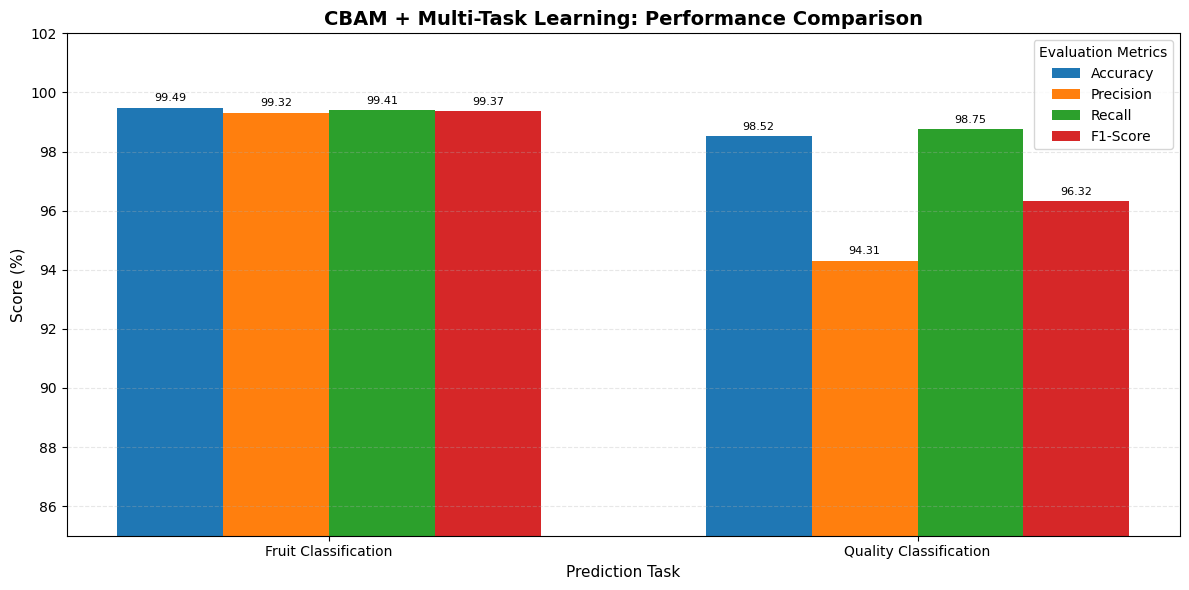

Graph saved as CBAM_MTL_Performance_Comparison.png


In [109]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# RESNET50 + CBAM + MULTI-TASK LEARNING
# Validation / test metric comparison
# ==========================================

tasks = [
    "Fruit Classification",
    "Quality Classification"
]

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

# Values reported by your model (percentage)
fruit_scores = [99.49, 99.32, 99.41, 99.37]
quality_scores = [98.52, 94.31, 98.75, 96.32]

data = np.array([fruit_scores, quality_scores])

# ==========================================
# GROUPED BAR CHART
# ==========================================

x = np.arange(len(tasks))
bar_width = 0.18

fig, ax = plt.subplots(figsize=(12, 6))

for i, metric in enumerate(metrics):
    bars = ax.bar(
        x + (i - 1.5) * bar_width,
        data[:, i],
        bar_width,
        label=metric
    )

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3,
        fontsize=8,
        rotation=0
    )

ax.set_title(
    "CBAM + Multi-Task Learning: Performance Comparison",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Prediction Task", fontsize=11)
ax.set_ylabel("Score (%)", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(tasks)

ax.set_ylim(85, 102)
ax.legend(title="Evaluation Metrics", loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

# Save high-resolution figure for your report
plt.savefig(
    "/content/CBAM_MTL_Performance_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved as CBAM_MTL_Performance_Comparison.png")
